In [ ]:
#@title

from IPython.display import display, HTML

display(HTML("""
<div id="top" style="
    background: #0b1020;
    color: #e8edff;
    padding: 28px;
    border-radius: 12px;
    font-family: Arial, sans-serif;
    font-size: 14px;
    line-height: 1.8;
    width: 100%;
    box-sizing: border-box;
">
    <h1 style="
        color: #ffffff;
        font-size: 27px;
        line-height: 1.35;
        margin: 0 0 24px 0;
    ">
        Лабораторная работа 01 — статистическое исследование объектов Gaia DR3
    </h1>

    <p style="margin: 0 0 14px 0;">
        <strong style="color: #b9a8ff;">Тема:</strong>
        как распределены видимая яркость, цвет и параллакс объектов Gaia
        и что меняется при выборе только самых ярких объектов.
    </p>

    <p style="margin: 0 0 28px 0;">
        <strong style="color: #b9a8ff;">Команда:</strong>
        три инфохимика · общая аналитическая часть для последующего оформления дизайнерами
    </p>

    <p style="color: #c6d2ff; font-size: 19px; font-weight: 600; margin-bottom: 12px;">
        В работе исследуются три случайные величины:
    </p>

    <ol style="padding-left: 24px; margin: 0 0 26px 0;">
        <li style="padding: 3px 0;">
            видимая звёздная величина
            <code style="color: #c4b5fd; background: #1b2440; padding: 2px 6px; border-radius: 4px;">G</code>
            — участник 1;
        </li>
        <li style="padding: 3px 0;">
            цвет
            <code style="color: #c4b5fd; background: #1b2440; padding: 2px 6px; border-radius: 4px;">BP − RP</code>
            — участник 2;
        </li>
        <li style="padding: 3px 0;">измеренный параллакс — участник 3.</li>
    </ol>

    <div style="
        background: #131c33;
        border-left: 3px solid #8b9dff;
        padding: 16px 18px;
        border-radius: 0 8px 8px 0;
        margin: 0 0 24px 0;
    ">
        <p style="color: #c6d2ff; font-size: 18px; font-weight: 600; margin: 0 0 8px 0;">
            Главный вопрос работы
        </p>
        <p style="margin: 0;">
            Главный вопрос работы: можно ли по случайной выборке объектов Gaia судить о всей выбранной базе и как меняется вывод, если выбирать объекты не случайно, а по яркости.
        </p>
    </div>

    <div style="
        background: #171b32;
        border: 1px solid #343b60;
        padding: 16px 18px;
        border-radius: 8px;
    ">
        <p style="color: #c4b5fd; font-size: 17px; font-weight: 600; margin: 0 0 8px 0;">
            Важно про область вывода.
        </p>
        <p style="margin: 0;">
            Генеральная совокупность в этой лабораторной — конечная рабочая база из 10 000 объектов Gaia DR3. Это не все звёзды Вселенной и не все объекты Млечного Пути. Поэтому выводы относятся к этой базе и к способу её формирования.
        </p>
    </div>
</div>
"""))

In [ ]:
# @title
from IPython.display import display, HTML

display(HTML("""
<div style="
    background: #111827;
    color: #F8FAFC;
    padding: 20px 24px;
    border-left: 5px solid #A78BFA;
    border-radius: 10px;
    font-family: Arial, sans-serif;
    box-sizing: border-box;
">
    <h1 style="
        color: #F8FAFC;
        margin: 0;
        font-size: 28px;
        font-weight: 700;
        line-height: 1.5;
    ">
        Оглавление
    </h1>
</div>
"""))

## Спринт 1 — статистическое исследование

1. [Данные и способ их получения](#scrollTo=P696gGLiHgzm)
2. [Что в работе считается случайной величиной](#scrollTo=bifbY3pFRBLI&line)
3. [Случайная величина 01 — видимая звёздная величина G](#scrollTo=vVpQ97tmTNPO&line)
4. [Случайная величина 02 — цвет BP − RP](#scrollTo=WVZ32rZaWUM0&line)
5. [Случайная величина 03 — измеренный параллакс](#scrollTo=Du3q5SfGf7CI&line)
6. [Зависимость между тремя величинами](#scrollTo=5Nz9obxigDf9&line)
7. [Генеральная совокупность, выборки и состоятельность оценок](#scrollTo=69PFOIvTgJFN&line)
8. [Проверка статистических гипотез](#scrollTo=Z0B2vmdNgNp7&line)
9. [Эксперимент: что меняется при выборе самых ярких объектов](#scrollTo=RbbL6zxygUaq&line)

## Спринт 2 — генераторы случайных величин

10. [Зачем нужен генератор](#scrollTo=mS4-NF-vgaNK&line)
11. [Математическое описание алгоритмов](#scrollTo=XoH_P8o_gfum&line)
12. [Автоматические проверки генераторов](#scrollTo=Wiq5NkKmgsPx&line)

## Итоги

13. [Итоговые выводы](#scrollTo=8VdXGaagdv40)
14. [Карта требований лабораторной работы](#scrollTo=NbxfodBWdl33)
15. [Литература и источники](#scrollTo=yM1b_5ePdgqA)

In [ ]:
# @title
from IPython.display import display, HTML

display(HTML("""
<div id="data" style="
    background: #111827;
    color: #F8FAFC;
    padding: 20px 24px;
    border: 1px solid #475569;
    border-left: 5px solid #A78BFA;
    border-radius: 10px;
    font-family: Arial, sans-serif;
    box-sizing: border-box;
">
    <h2 style="
        color: #F8FAFC;
        margin: 0;
        font-size: 23px;
        font-weight: 700;
        line-height: 1.5;
    ">
        1. Данные и способ их получения
    </h2>
</div>
"""))

<a id="data"></a>
Источник данных — официальный архив **Gaia Data Release 3**, таблица `gaiadr3.gaia_source` [1, 2]. Из архива была выгружена ограниченная часть каталога с заполненными значениями трёх основных характеристик. В запросе использован `random_index`, который задаёт случайную перестановку строк каталога.

```sql
SELECT source_id, random_index, ra, dec, phot_g_mean_mag, bp_rp,
       parallax, parallax_error, ruwe, phot_g_mean_flux_over_error
FROM gaiadr3.gaia_source
WHERE random_index < 20000
  AND phot_g_mean_mag IS NOT NULL
  AND bp_rp IS NOT NULL
  AND parallax IS NOT NULL
ORDER BY random_index
```

Из 14 932 подходящих строк после проверки качества взяты первые 10 000. В ноутбук встроена контрольная копия исходной выгрузки, поэтому для воспроизведения не нужно заново скачивать данные.

Отрицательные измеренные параллаксы не удаляются. Они возможны из-за ошибок измерения малых величин; отрицательный параллакс не означает физическое отрицательное расстояние [3].


In [ ]:
# @title
from IPython.display import display, HTML

display(HTML("""
<div style="font-family: Arial, sans-serif; margin: 16px 0;">
<table style="
    width: 100%;
    border-collapse: separate;
    border-spacing: 0;
    border-radius: 10px;
    overflow: hidden;
    border: 1px solid #D8D4F0;
    font-size: 14px;
    color: #1F2937;
">
<thead>
<tr style="background: #111827; color: #F8FAFC;">
    <th style="padding: 14px; text-align: left;">Столбец</th>
    <th style="padding: 14px; text-align: left;">Простое объяснение</th>
    <th style="padding: 14px; text-align: left;">Единицы</th>
</tr>
</thead>
<tbody>
<tr style="background: #F5F3FF;">
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;"><code>phot_g_mean_mag</code></td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">Видимая звёздная величина G; чем меньше число, тем ярче объект</td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">mag</td>
</tr>
<tr style="background: #FFFFFF;">
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;"><code>bp_rp</code></td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">Разность синего и красного каналов; большее значение обычно означает более красный цвет</td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">mag</td>
</tr>
<tr style="background: #F5F3FF;">
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;"><code>parallax</code></td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">Измеренное годовое угловое смещение объекта из-за движения Земли</td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">mas</td>
</tr>
<tr style="background: #FFFFFF;">
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;"><code>parallax_error</code></td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">Стандартная ошибка измерения параллакса</td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">mas</td>
</tr>
<tr style="background: #F5F3FF;">
    <td style="padding: 12px;"><code>ruwe</code></td>
    <td style="padding: 12px;">Показатель качества астрометрического решения</td>
    <td style="padding: 12px;">Без единицы</td>
</tr>
</tbody>
</table>
</div>
"""))

Столбец,Простое объяснение,Единицы
phot_g_mean_mag,"Видимая звёздная величина G; чем меньше число, тем ярче объект",mag
bp_rp,Разность синего и красного каналов; большее значение обычно означает более красный цвет,mag
parallax,Измеренное годовое угловое смещение объекта из-за движения Земли,mas
parallax_error,Стандартная ошибка измерения параллакса,mas
ruwe,Показатель качества астрометрического решения,Без единицы


In [ ]:
#@title Библиотеки и оформление графиков { display-mode: "form" }
import base64, hashlib, io, json, math, time, unittest, zlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special

OUT = Path('gaia_team_results')
OUT.mkdir(exist_ok=True)
SEED = 20261020
ALPHA = 0.05

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,

    # Космическая палитра
    'figure.facecolor': '#0b1020',
    'axes.facecolor': '#131b30',
    'savefig.facecolor': '#0b1020',
    'text.color': '#edf3ff',
    'axes.labelcolor': '#edf3ff',
    'axes.edgecolor': '#34415f',
    'xtick.color': '#edf3ff',
    'ytick.color': '#edf3ff',

    # Сетка и границы
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#34415f',
    'grid.alpha': 0.45,
    'grid.linestyle': '--',

    'figure.dpi': 120,
    'savefig.dpi': 160,
})

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
COLORS = {
    'G': '#7AA2F7',          # голубой
    'BP−RP': '#7EE0C3',      # бирюзовый
    'Параллакс': '#F7768E',  # кораллово-розовый
    'mean': '#E0AF68',       # золотистый
    'median': '#BB9AF7',     # фиолетовый
    'bright': '#FF79C6'      # ярко-розовый
}

In [ ]:
# @title Загрузка общей таблицы Gaia DR3

import io
import hashlib
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML

file_path = Path("gaia_team.csv")

if file_path.exists():
    filename = file_path.name
    raw_bytes = file_path.read_bytes()
else:
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    raw_bytes = uploaded[filename]

raw = pd.read_csv(
    io.BytesIO(raw_bytes),
    dtype={"source_id": "string"}
)

PROVENANCE = {
    "catalogue": "Gaia DR3",
    "table": "gaiadr3.gaia_source",
    "query": "Готовая командная таблица Gaia DR3, подготовленная командой",
    "retrieved_utc": "2026-10-18",
    "raw_sha256": hashlib.sha256(raw_bytes).hexdigest()
}

display(HTML(f"""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    background: #F5F3FF;
    border-left: 4px solid #8B7BD8;
    border-radius: 8px;
    padding: 12px 16px;
    line-height: 1.8;
">
    <div><b>Файл прочитан:</b> {filename}</div>
    <div><b>Размер таблицы:</b> {raw.shape}</div>
    <div><b>Столбцы:</b> {list(raw.columns)}</div>
</div>
"""))

In [ ]:
#@title Подготовка данных и контроль качества

main_columns = ['phot_g_mean_mag', 'bp_rp', 'parallax']

for column in raw.columns:
    if column != 'source_id':
        raw[column] = pd.to_numeric(raw[column], errors='coerce')

valid = np.isfinite(raw[main_columns].to_numpy(dtype=float)).all(axis=1)
prepared = raw.loc[valid].copy()

duplicates = int(prepared['source_id'].duplicated().sum())

if duplicates:
    raise ValueError(f'Повторные source_id: {duplicates}')

if len(prepared) < 10000:
    raise ValueError('В выгрузке меньше 10 000 полных строк.')

df = prepared.sort_values(
    'random_index', kind='stable'
).head(10000).reset_index(drop=True)

N = len(df)

df.to_csv(OUT/'gaia_team.csv', index=False)

PROVENANCE['team_rows'] = N
PROVENANCE['selection'] = 'First 10000 complete rows ordered by archive random_index'

(OUT/'provenance.json').write_text(
    json.dumps(PROVENANCE, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

(OUT/'gaia_query.sql').write_text(
    PROVENANCE['query'],
    encoding='utf-8'
)

quality = pd.DataFrame({
    'Проверка': [
        'Строк в исходной выгрузке',
        'Полных строк после проверки',
        'Строк в рабочей базе',
        'Повторных source_id',
        'Отрицательных параллаксов'
    ],
    'Результат': [
        len(raw),
        len(prepared),
        N,
        duplicates,
        int((df.parallax < 0).sum())
    ]
})

quality.to_csv(OUT/'data_quality.csv', index=False)

# Оформление таблицы контроля качества
from IPython.display import display, HTML
from html import escape

rows_html = ''

for i, row in quality.iterrows():
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'
    rows_html += f"""
    <tr style="background:{bg};">
        <td style="padding:12px 14px; border-bottom:1px solid #E5E7EB;">
            {escape(str(row['Проверка']))}
        </td>
        <td style="padding:12px 14px; border-bottom:1px solid #E5E7EB;">
            {escape(str(row['Результат']))}
        </td>
    </tr>
    """

display(HTML(f"""
<div style="font-family:Arial,sans-serif; margin:16px 0;">
<table style="
    width:100%;
    border-collapse:separate;
    border-spacing:0;
    border-radius:10px;
    overflow:hidden;
    border:1px solid #D8D4F0;
    font-size:14px;
    color:#1F2937;
">
    <thead>
        <tr style="background:#111827; color:#F8FAFC;">
            <th style="padding:14px; text-align:left; border-bottom:1px solid #475569;">
                Проверка
            </th>
            <th style="padding:14px; text-align:left; border-bottom:1px solid #475569;">
                Результат
            </th>
        </tr>
    </thead>
    <tbody>
        {rows_html}
    </tbody>
</table>
</div>
"""))

Проверка,Результат
Строк в исходной выгрузке,10000
Полных строк после проверки,10000
Строк в рабочей базе,10000
Повторных source_id,0
Отрицательных параллаксов,2345


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
2. Что в работе считается случайной величиной
</h2></div>
"""))

<a id="random-variables"></a>
Строки каталога сами по себе уже содержат зафиксированные измерения. Случайный опыт задаём так: **равновероятно выбираем одну строку рабочей базы**. Если (I) — номер выбранной строки, то

$$
P(I=i)=\frac1N,\qquad N=10000.
$$

Тогда случайными величинами являются характеристики выбранного объекта:

$$
G=G_I,\qquad C=(BP-RP)_I,\qquad \Pi=\mathrm{parallax}_I.
$$

До выбора строки мы не знаем, какой объект попадёт в опыт, поэтому не можем заранее вычислить значение только по номеру будущей строки. Значения различаются из-за различий объектов, расстояний, спектров, поглощения света и ошибок измерений. Для фиксированной уже выбранной строки число становится известным.

Такое обоснование относится к **случайному выбору объекта из базы**. Оно не утверждает, что все звёзды Вселенной распределены так же, как строки этой выгрузки.


<a id="helpers"></a>
### Общие определения статистик и моделей

Для каждой величины считаются среднее, медиана, дисперсия, стандартное отклонение, квартили, асимметрия и эксцесс. Дисперсия с делителем (N) описывает разброс всей конечной базы, а дисперсия с делителем (N-1) — стандартная исправленная оценка по выборке:

$$
\mu_N=\frac1N\sum_{i=1}^{N}x_i,
\qquad
v_N=\frac1N\sum_{i=1}^{N}(x_i-\mu_N)^2,
\qquad
s^2=\frac1{n-1}\sum_{i=1}^{n}(x_i-\bar x)^2.
$$

Для формы распределения сравниваются нормальная модель, распределение Лапласа и асимметричная нормальная модель. Кроме того, для конечной базы всегда существует точное **эмпирическое распределение**: каждая строка имеет вероятность (1/N). Параметрические модели являются приближениями, а эмпирическое распределение точно описывает случайный выбор из этой базы.
*Параметрические распределения и статистические функции рассчитываются с использованием SciPy [6].*


In [ ]:

#@title Общие функции анализа и построения графиков
FEATURES = [
    {'key':'G', 'column':'phot_g_mean_mag', 'label':'G', 'long':'Видимая звёздная величина G', 'unit':'mag', 'color':COLORS['G']},
    {'key':'BP−RP', 'column':'bp_rp', 'label':'BP − RP', 'long':'Показатель цвета BP − RP', 'unit':'mag', 'color':COLORS['BP−RP']},
    {'key':'Параллакс', 'column':'parallax', 'label':'Параллакс', 'long':'Измеренный параллакс', 'unit':'mas', 'color':COLORS['Параллакс']},
]

def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    adjusted_sorted = np.minimum(1.0, np.maximum.accumulate(
        pvalues[order] * (len(pvalues) - np.arange(len(pvalues)))))
    adjusted = np.empty_like(pvalues)
    adjusted[order] = adjusted_sorted
    return adjusted

def describe_feature(values, unit, label):
    a = np.asarray(values, dtype=float)
    q1, med, q3 = np.quantile(a, [.25, .5, .75])
    iqr = q3-q1
    flags = (a < q1-1.5*iqr) | (a > q3+1.5*iqr)
    return pd.DataFrame({
        'Показатель':['Число объектов','Среднее','Медиана','Дисперсия базы (N)','Исправленная дисперсия','Стандартное отклонение',
                      'Минимум','Q1','Q3','Максимум','IQR','Асимметрия','Эксцесс','Отмечено правилом 1.5 IQR'],
        'Значение':[len(a),a.mean(),med,a.var(ddof=0),a.var(ddof=1),a.std(ddof=1),a.min(),q1,q3,a.max(),iqr,
                    stats.skew(a,bias=False),stats.kurtosis(a,bias=False),int(flags.sum())],
        'Единицы':[ 'объектов',unit,unit,unit+'²',unit+'²',unit,unit,unit,unit,unit,unit,
                    'безразмерная','безразмерный','объектов']
    }), flags

def fit_models_train_test(values, key):
    a = np.asarray(values, dtype=float)
    # Explicit seeds keep the train/test split reproducible across Python processes.
    seed_by_key = {'G':1101, 'BP−RP':1102, 'Параллакс':1103}[key]
    idx = np.random.default_rng(SEED+seed_by_key).permutation(len(a))
    n_train = int(.7*len(a))
    train, test = a[idx[:n_train]], a[idx[n_train:]]
    specs = {'Нормальная': stats.norm, 'Лапласа': stats.laplace, 'Асимметричная нормальная': stats.skewnorm}
    rows=[]; fitted={}
    for name, dist in specs.items():
        params = tuple(float(v) for v in dist.fit(train))
        fitted[name] = (dist, params)
        loglik = float(dist.logpdf(train, *params).sum())
        pcount = len(params)
        result = stats.kstest(test, dist.cdf, args=params)
        density = np.maximum(dist.pdf(test, *params), 1e-300)
        rows.append({'Модель':name,'Обучение, n':len(train),'Контроль, n':len(test),'Параметров':pcount,
                     'AIC':2*pcount-2*loglik,'BIC':pcount*np.log(len(train))-2*loglik,
                     'KS D на контроле':result.statistic,'p на контроле':result.pvalue,
                     'Средний log-loss':-np.log(density).mean()})
    table = pd.DataFrame(rows)
    table['p_Holm'] = holm_adjust(table['p на контроле'].to_numpy())
    table['Решение при α=0,05'] = np.where(table['p_Holm']<ALPHA,'Отвергаем H₀','Нет оснований отвергать H₀')
    table = table.sort_values('BIC').reset_index(drop=True)
    return table, fitted, train, test

def plot_eda(values, info, out_prefix):
    a = np.asarray(values, dtype=float)
    q1,q3=np.quantile(a,[.25,.75]); iqr=q3-q1
    ordered=np.sort(a)
    fig, axes = plt.subplots(1,3,figsize=(14,4),constrained_layout=True)

    axes[0].hist(
        a, bins='fd', color=info['color'],
        edgecolor='#F8FAFC', linewidth=0.8, density=False
    )
    axes[0].axvline(
        a.mean(), color=COLORS['mean'], linewidth=2,
        label=f'среднее = {a.mean():.3f}'
    )
    axes[0].axvline(
        np.median(a), color=COLORS['median'], ls='--', linewidth=2,
        label=f'медиана = {np.median(a):.3f}'
    )
    axes[0].set(
        xlabel=f"{info['label']}, {info['unit']}",
        ylabel='Число объектов',
        title=f"Гистограмма: {info['long']}"
    )
    axes[0].legend(frameon=False,fontsize=8)

    axes[1].boxplot(
        a,
        vert=True,
        patch_artist=True,
        boxprops={
            'facecolor': '#263550',
            'edgecolor': '#A78BFA',
            'linewidth': 1.8
        },
        medianprops={
            'color': '#FF79C6',
            'linewidth': 2.5
        },
        whiskerprops={
            'color': '#7AA2F7',
            'linewidth': 1.8
        },
        capprops={
            'color': '#7AA2F7',
            'linewidth': 1.8
        },
        flierprops={
            'marker': 'o',
            'markerfacecolor': '#F7768E',
            'markeredgecolor': '#F8FAFC',
            'markersize': 3,
            'alpha': 0.55
        }
    )
    axes[1].set(
        ylabel=f"{info['label']}, {info['unit']}",
        title='Квартили и отмеченные значения',
        xticks=[]
    )

    axes[2].step(
        ordered, np.arange(1,len(a)+1)/len(a),
        where='post', color=info['color'], linewidth=1.8
    )
    axes[2].set(
        xlabel=f"{info['label']}, {info['unit']}",
        ylabel='Доля объектов ≤ x',
        title='Эмпирическая функция распределения',
        ylim=(0,1.02)
    )

    for ax in axes:
        ax.grid(alpha=.18, linestyle='--')
        ax.set_axisbelow(True)

    fig.savefig(OUT/(out_prefix+'_eda.png'),bbox_inches='tight')
    plt.show()

def plot_models(values, info, fit_table, fitted, out_prefix):
    a = np.asarray(values,float)
    grid = np.linspace(
        a.min()-.05*(a.max()-a.min()),
        a.max()+.05*(a.max()-a.min()),
        1200
    )
    ordered = np.sort(a)
    ec = np.arange(1,len(a)+1)/len(a)

    fig,axes = plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)

    axes[0].hist(
        a, bins='fd', density=True,
        color='#263550',
        edgecolor='#A78BFA',
        linewidth=0.8,
        alpha=0.9,
        label='Данные'
    )
    axes[1].step(
        ordered, ec, where='post',
        color=info['color'],
        linewidth=1.8,
        label='Эмпирическая CDF'
    )

    colors = {
        'Нормальная': '#F7768E',
        'Лапласа': '#E0AF68',
        'Асимметричная нормальная': '#7EE0C3'
    }

    for name,(dist,params) in fitted.items():
        axes[0].plot(
            grid,dist.pdf(grid,*params),
            label=name,color=colors[name],lw=2
        )
        axes[1].plot(
            grid,dist.cdf(grid,*params),
            label=name,color=colors[name],lw=1.8
        )

    axes[0].set(
        xlabel=f"{info['label']}, {info['unit']}",
        ylabel='Плотность',
        title='Данные и модели'
    )
    axes[1].set(
        xlabel=f"{info['label']}, {info['unit']}",
        ylabel='Доля объектов',
        title='Эмпирическая CDF и модели',
        ylim=(0,1.03)
    )

    for ax in axes:
        ax.legend(frameon=False,fontsize=8)
        ax.grid(alpha=.18,linestyle='--')
        ax.set_axisbelow(True)

    fig.savefig(OUT/(out_prefix+'_models.png'),bbox_inches='tight')
    plt.show()


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
3. Случайная величина 01 — видимая звёздная величина G
</h2></div>
"""))

<a id="rv01"></a>

### Что измеряется и почему это случайная величина

`G` — видимая звёздная величина. Это логарифмическая шкала наблюдаемого потока: меньшему числу соответствует более яркий объект. Она не равна собственной светимости звезды: на результат влияют расстояние и поглощение света.

В опыте случайно выбирается объект из рабочей базы, а (G) выбранной строки становится значением случайной величины. До выбора неизвестно, какой объект выпадет, поэтому значение нельзя заранее вычислить одной формулой.


Показатель,Значение,Единицы
Число объектов,10000.000,объектов
Среднее,18.939,mag
Медиана,19.339,mag
Дисперсия базы (N),2.472,mag²
Исправленная дисперсия,2.473,mag²
Стандартное отклонение,1.572,mag
Минимум,9.903,mag
Q1,18.189,mag
Q3,20.105,mag
Максимум,21.030,mag


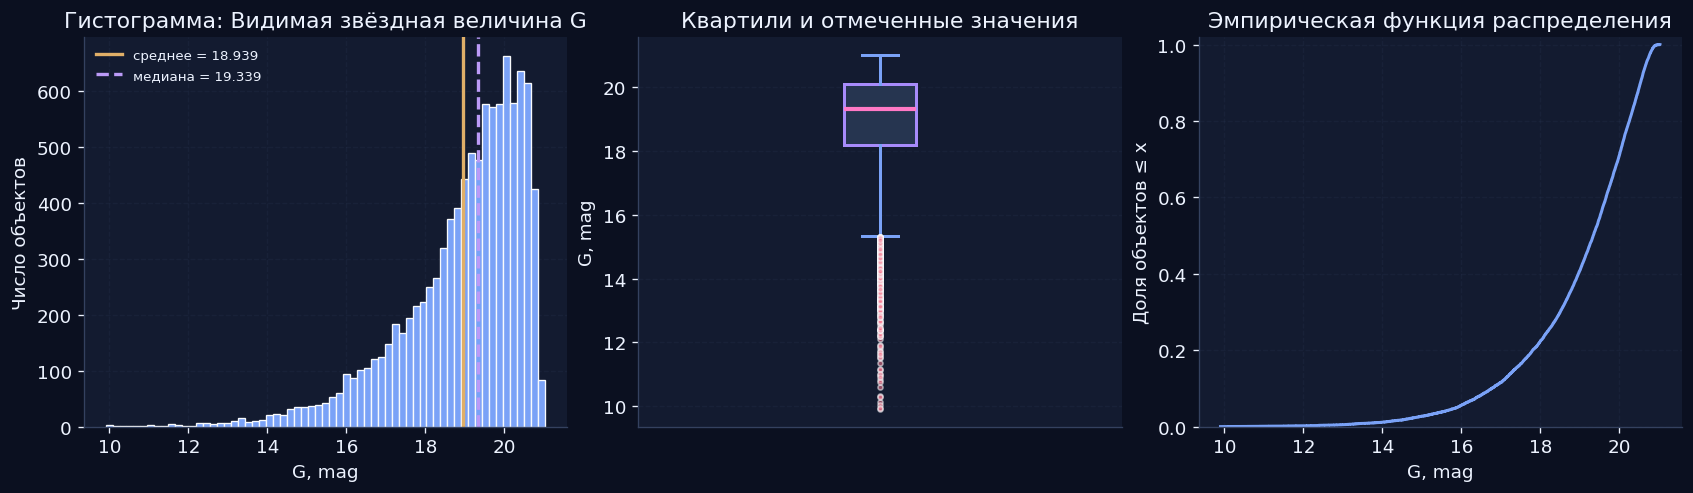

In [ ]:

# @title Описательная статистика: видимая звёздная величина G

from IPython.display import display, HTML
from html import escape

info = FEATURES[0]
a = df[info['column']].to_numpy(float)

summary_G, flags_G = describe_feature(a, info['unit'], info['label'])
summary_G.to_csv(OUT / 'G_summary.csv', index=False)


# Описательная статистика
display(
    summary_G.style
    .format(precision=3)
    .set_caption('Описательная статистика: видимая звёздная величина G')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '15px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('color', '#F8FAFC'),
                ('background-color', '#111827'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('text-align', 'left'),
                ('padding', '10px'),
                ('border-bottom', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd) td',
            'props': [
                ('background-color', '#F5F3FF')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(even) td',
            'props': [
                ('background-color', '#FFFFFF')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('border', '1px solid #D8D4F0'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px')
            ]
        }
    ])
    .hide(axis='index')
)


# Графики
plot_eda(a, info, 'G')


# Оформленный вывод
display(HTML(f"""
<div style="
    font-family:Arial,sans-serif;
    margin:20px 0;
    border:1px solid #D8D4F0;
    border-radius:10px;
    overflow:hidden;
    color:#1F2937;
">
    <div style="
        background:#111827;
        color:#F8FAFC;
        padding:14px 18px;
        font-size:16px;
        font-weight:bold;
    ">
        Вывод по звёздной величине G
    </div>

    <div style="
        background:#F5F3FF;
        padding:16px 18px;
        font-size:14px;
        line-height:1.7;
    ">
        <div style="margin-bottom:10px;">
            <b>Среднее:</b> {a.mean():.4f} mag
            <span style="color:#9CA3AF;"> · </span>
            <b>Медиана:</b> {np.median(a):.4f} mag
        </div>

        <div style="margin-bottom:10px;">
            Медиана выше среднего. Это согласуется с наличием хвоста
            распределения в сторону меньших значений G — более ярких объектов.
        </div>

        <div>
            <b>Выбросы по правилу 1.5 IQR:</b> {int(flags_G.sum())}.
            Эти наблюдения не удаляются: среди них могут быть реальные яркие объекты.
        </div>
    </div>
</div>
"""))


### Нормализация G

Для сравнения признаков с разными единицами используем два преобразования:

$$
u=\frac{G-G_{\min}}{G_{\max}-G_{\min}},
\qquad
z=\frac{G-\bar G}{s}.
$$

После min–max все значения лежат от 0 до 1. После стандартизации среднее равно 0, а исправленное стандартное отклонение равно 1. Эти преобразования меняют шкалу, но не делают распределение нормальным автоматически.


Показатель,Значение
min–max min,0.00000000
min–max max,1.00000000
Z среднее,-0.00000000
Z s (N−1),1.00000000


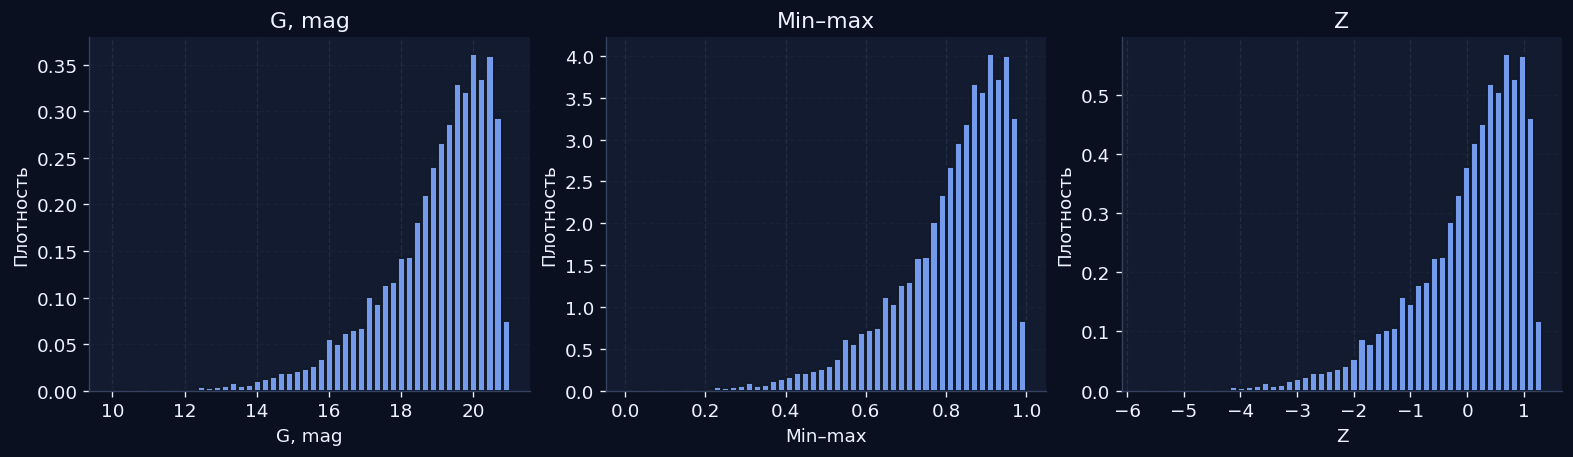

In [ ]:
# @title

def scale_feature(values, info, prefix):
    a = np.asarray(values, float)
    u = (a - a.min()) / (a.max() - a.min())
    z = (a - a.mean()) / a.std(ddof=1)

    result = pd.DataFrame({
        'Исходное': a,
        'Min–max': u,
        'Z': z
    })
    result.to_csv(OUT/(prefix+'_scaled.csv'), index=False)

    check = pd.DataFrame({
        'Показатель': ['min–max min', 'min–max max', 'Z среднее', 'Z s (N−1)'],
        'Значение': [u.min(), u.max(), z.mean(), z.std(ddof=1)]
    })

    display(
        check.round(8).style
        .format(precision=8)
        .set_caption('Проверка масштабирования')
        .set_table_styles([
            {'selector': 'caption', 'props': [
                ('caption-side', 'top'),
                ('font-size', '15px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('color', '#F8FAFC'),
                ('background-color', '#111827'),
                ('padding', '12px'),
                ('border-radius', '8px 8px 0 0')
            ]},
            {'selector': 'th', 'props': [
                ('background-color', '#1E293B'),
                ('color', '#F8FAFC'),
                ('text-align', 'left'),
                ('padding', '10px'),
                ('border-bottom', '2px solid #A78BFA')
            ]},
            {'selector': 'td', 'props': [
                ('background-color', '#F5F3FF'),
                ('color', '#1F2937'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #D8D4F0')
            ]},
            {'selector': 'table', 'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('border', '1px solid #D8D4F0'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '12px')
            ]}
        ])
        .hide(axis='index')
    )

    assert np.isclose(u.min(), 0) and np.isclose(u.max(), 1)
    assert np.isclose(z.mean(), 0, atol=1e-12)
    assert np.isclose(z.std(ddof=1), 1)

    fig, ax = plt.subplots(
        1, 3, figsize=(13, 3.7), constrained_layout=True
    )

    plot_data = [
        (a, f"{info['label']}, {info['unit']}"),
        (u, 'Min–max'),
        (z, 'Z')
    ]

    for axis, (v, label) in zip(ax, plot_data):
        axis.hist(
    v,
    bins=50,
    color=info['color'],
    edgecolor='#111827',
    linewidth=1.2,
    rwidth=0.88,
    density=True,
    alpha=0.95
)
        axis.set(
            xlabel=label,
            ylabel='Плотность',
            title=label
        )
        axis.grid(axis='y', alpha=0.18, linestyle='--')
        axis.set_axisbelow(True)

    fig.savefig(
        OUT/(prefix+'_scaling.png'),
        bbox_inches='tight'
    )
    plt.show()

    return result


scaled_G = scale_feature(a, info, 'G')


### Математическая модель распределения G

Нормальное распределение удобно как симметричная модель сравнения. Лапласовское распределение допускает более тяжёлые хвосты. Асимметричная нормальная модель дополнительно допускает скошенность.

Параметры моделей оцениваются только на обучающей части данных, а проверка согласия проводится на независимой контрольной части. Поэтому p-value не искажается тем, что параметры были подогнаны на тех же значениях.



Модель,"Обучение, n","Контроль, n",Параметров,AIC,BIC,KS D на контроле,p на контроле,Средний log-loss,p_Holm,"Решение при α=0,05"
Асимметричная нормальная,7000,3000,3,23265.004651,23285.565647,0.070816,0.000000,1.626349,0.000000,Отвергаем H₀
Лапласа,7000,3000,2,26036.827625,26050.534956,0.129142,0.000000,1.810992,0.000000,Отвергаем H₀
Нормальная,7000,3000,2,26348.947255,26362.654586,0.130846,0.000000,1.848276,0.000000,Отвергаем H₀


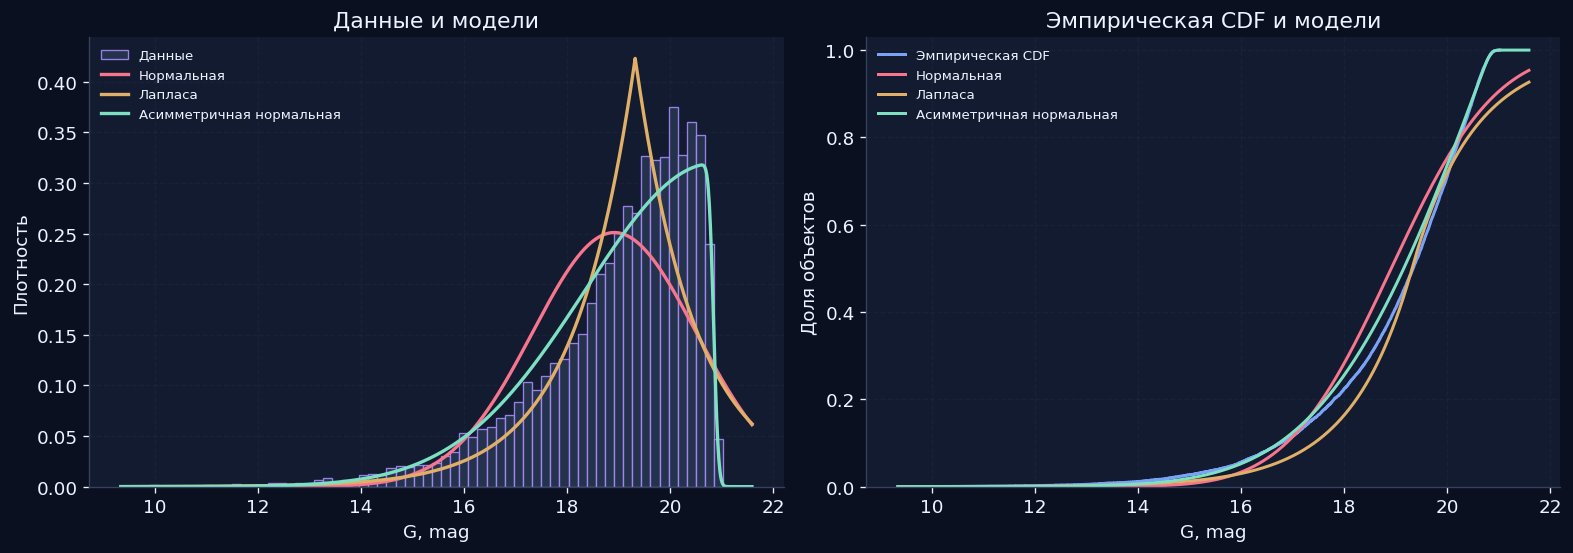

In [ ]:

# @title Модели распределения звёздной величины G

models_G, fitted_G, train_G, test_G = fit_models_train_test(a, 'G')
models_G.to_csv(OUT / 'G_distribution_models.csv', index=False)


# Таблица сравнения моделей
display(
    models_G.round(6).style
    .set_caption('Сравнение моделей распределения звёздной величины G')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '15px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('color', '#F8FAFC'),
                ('background-color', '#111827'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('text-align', 'left'),
                ('padding', '10px'),
                ('border-bottom', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd) td',
            'props': [
                ('background-color', '#F5F3FF')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(even) td',
            'props': [
                ('background-color', '#FFFFFF')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('border', '1px solid #D8D4F0'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px')
            ]
        }
    ])
    .hide(axis='index')
)


# Графики моделей
plot_models(a, info, models_G, fitted_G, 'G')


# Итоговый вывод
display(HTML("""
<div style="
    font-family:Arial,sans-serif;
    margin:20px 0;
    border:1px solid #D8D4F0;
    border-radius:10px;
    overflow:hidden;
    color:#1F2937;
">
    <div style="
        background:#111827;
        color:#F8FAFC;
        padding:14px 18px;
        font-size:16px;
        font-weight:bold;
    ">
        Вывод по моделям распределения G
    </div>
    <div style="
        background:#F5F3FF;
        padding:16px 18px;
        font-size:14px;
        line-height:1.7;
    ">
        Итоговая непрерывная модель выбирается по BIC, но точное
        распределение случайного выбора из конечной базы задаётся
        эмпирической CDF.
    </div>
</div>
"""))


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
4. Случайная величина 02 — цвет BP − RP (участник 2)
</h2></div>
"""))

<a id="rv02"></a>
### Что означает цвет

`BP − RP` — разность измерений в синем и красном фотометрических каналах Gaia. Большие значения обычно соответствуют более красному наблюдаемому свету. Цвет зависит от спектра объекта, межзвёздного поглощения и качества измерения. По одному цвету нельзя точно восстановить температуру или химический состав звезды.

Случайной величиной считается цвет объекта, выбранного случайно из общей базы. Наблюдаемая конечная база задаёт дискретное эмпирическое распределение: одинаковые значения получают суммарную вероятность.


Показатель,Значение,Единицы
Число объектов,10000.000000,объектов
Среднее,1.620746,mag
Медиана,1.530344,mag
Дисперсия базы (N),0.372466,mag²
Исправленная дисперсия,0.372503,mag²
Стандартное отклонение,0.610331,mag
Минимум,-1.119076,mag
Q1,1.190716,mag
Q3,1.952171,mag
Максимум,7.030882,mag


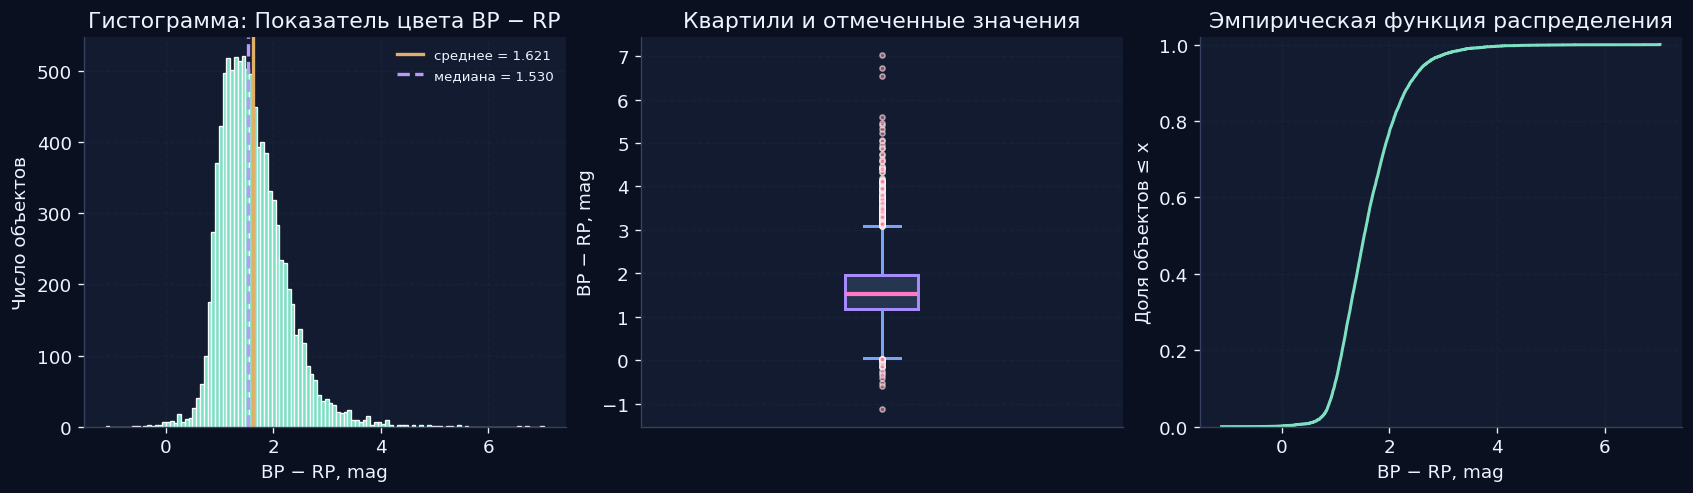

Показатель,Значение
min–max min,0.00000000
min–max max,1.00000000
Z среднее,-0.00000000
Z s (N−1),1.00000000


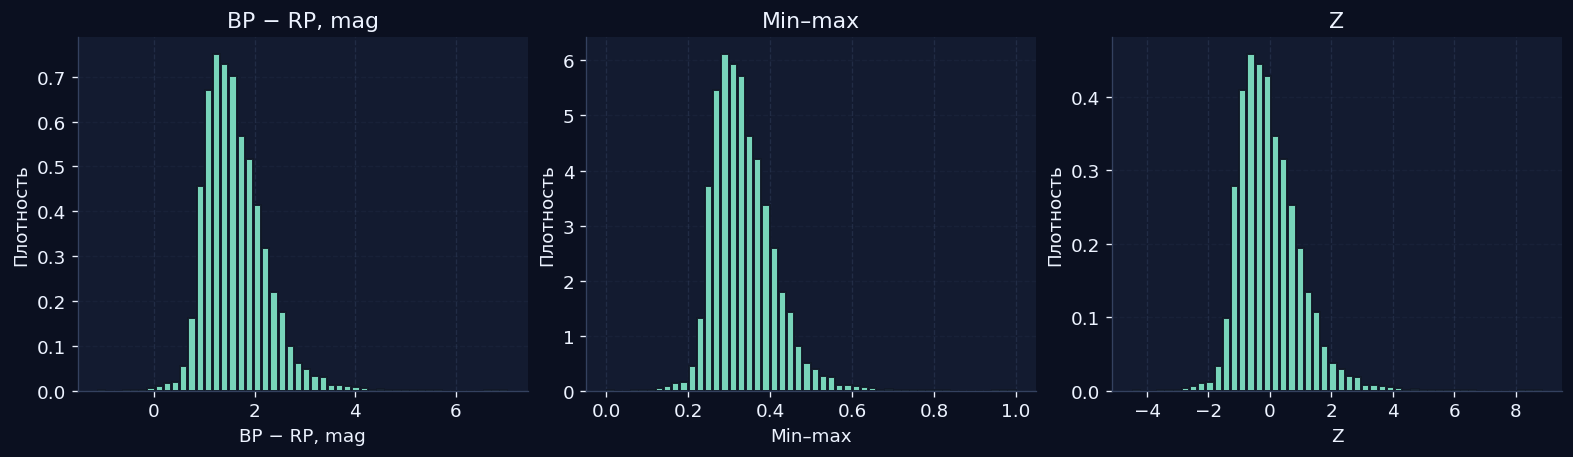

In [ ]:

# @title Описательная статистика: цвет BP-RP

from IPython.display import display, HTML

info = FEATURES[1]
a = df[info['column']].to_numpy(float)

summary_color, flags_color = describe_feature(
    a, info['unit'], info['label']
)
summary_color.to_csv(OUT / 'BP_RP_summary.csv', index=False)


# Таблица описательной статистики
display(
    summary_color.round(6).style
    .set_caption('Описательная статистика: цвет BP-RP')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '15px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('color', '#F8FAFC'),
                ('background-color', '#111827'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('text-align', 'left'),
                ('padding', '10px'),
                ('border-bottom', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd) td',
            'props': [
                ('background-color', '#F5F3FF')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(even) td',
            'props': [
                ('background-color', '#FFFFFF')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('border', '1px solid #D8D4F0'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px')
            ]
        }
    ])
    .hide(axis='index')
)


# Графики
plot_eda(a, info, 'BP_RP')


# Итоговый вывод
display(HTML(f"""
<div style="
    font-family:Arial,sans-serif;
    margin:20px 0;
    border:1px solid #D8D4F0;
    border-radius:10px;
    overflow:hidden;
    color:#1F2937;
">
    <div style="
        background:#111827;
        color:#F8FAFC;
        padding:14px 18px;
        font-size:16px;
        font-weight:bold;
    ">
        Вывод по цвету BP-RP
    </div>

    <div style="
        background:#F5F3FF;
        padding:16px 18px;
        font-size:14px;
        line-height:1.7;
    ">
        <div style="margin-bottom:10px;">
            <b>Среднее:</b> {a.mean():.4f} mag
            <span style="color:#9CA3AF;"> · </span>
            <b>Медиана:</b> {np.median(a):.4f} mag
        </div>

        <div>
            <b>Выбросы по правилу 1.5 IQR:</b> {int(flags_color.sum())}.
            Отмеченные значения не удаляются автоматически:
            сначала нужно определить, являются ли они ошибками
            или редкими объектами.
        </div>
    </div>
</div>
"""))


# Масштабирование признака для дальнейшего анализа
scaled_color = scale_feature(a, info, 'BP_RP')


### Математическая модель цвета

Для цвета проверяются те же три семейства. Дополнительно в работе сохраняется эмпирическое распределение как точная модель конечной базы. Если все непрерывные модели отвергаются, это означает, что они плохо описывают именно наблюдаемую рабочую базу; это не означает, что данные «не имеют распределения».


Модель,"Обучение, n","Контроль, n",Параметров,AIC,BIC,KS D на контроле,p на контроле,Средний log-loss,p_Holm,"Решение при α=0,05"
Асимметричная нормальная,7000,3000,3,12138.412515,12158.973511,0.021262,0.130821,0.864812,0.130821,Нет оснований отвергать H₀
Лапласа,7000,3000,2,12827.252729,12840.960060,0.065742,0.000000,0.912559,0.000000,Отвергаем H₀
Нормальная,7000,3000,2,13043.387181,13057.094512,0.057685,0.000000,0.910679,0.000000,Отвергаем H₀


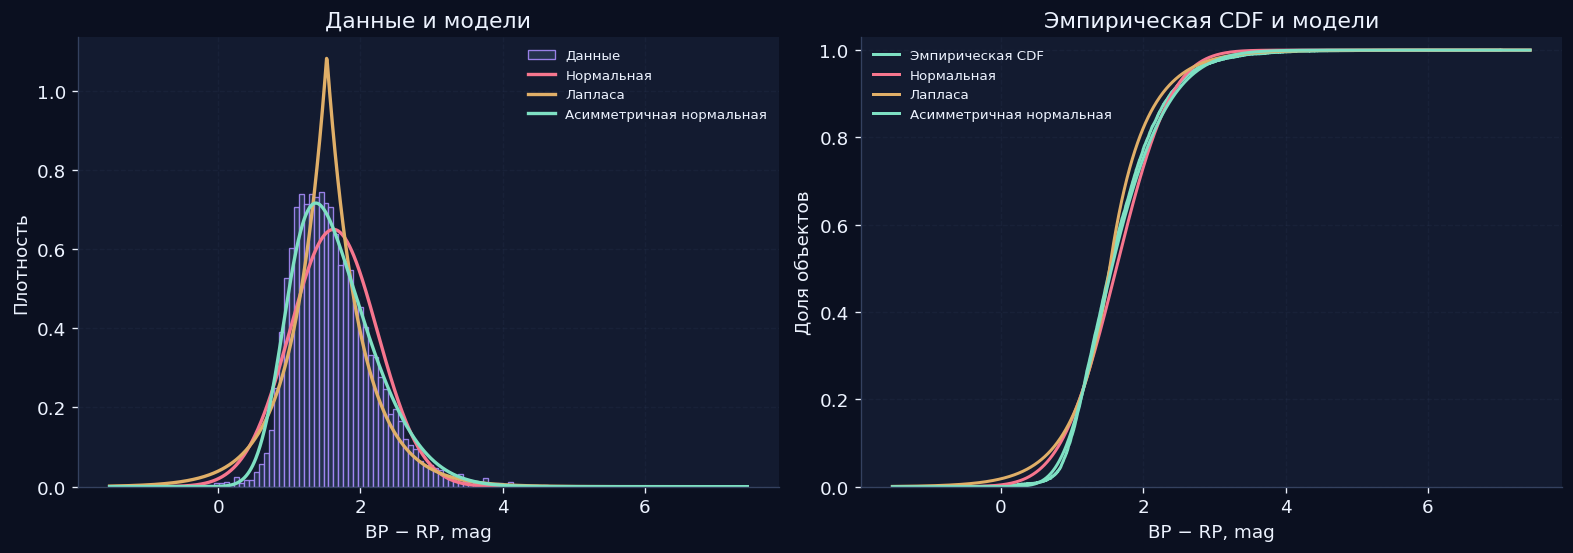

In [ ]:
# @title Модели распределения цвета BP-RP

from IPython.display import display, HTML

models_color, fitted_color, train_color, test_color = fit_models_train_test(
    a, 'BP−RP'
)

models_color.to_csv(
    OUT / 'BP_RP_distribution_models.csv',
    index=False
)

display(
    models_color.round(6).style
    .set_caption('Сравнение моделей распределения цвета BP-RP')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

plot_models(a, info, models_color, fitted_color, 'BP_RP')

display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по распределению цвета BP-RP
    </div>
    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">
        Форму распределения цвета интерпретируем по графику и таблице
        контрольных p-value. Для генерации используем эмпирическую CDF,
        если параметрические модели не проходят проверку.
    </div>
</div>
"""))

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
5. Случайная величина 03 — измеренный параллакс
</h2></div>
"""))

<a id="rv03"></a>
### Что означает параллакс

Параллакс — видимое годовое угловое смещение объекта, возникающее из-за движения Земли вокруг Солнца. Его используют для оценки расстояния, но в этой работе анализируется именно **измеренный параллакс**, а не величина (1/\pi). При малом сигнале ошибка измерения может быть сравнима с самим значением, поэтому отрицательные измерения сохраняются и рассматриваются как часть наблюдаемой статистики.

Параллакс случайно выбранного объекта — случайная величина: разные объекты находятся на разных расстояниях, а измерения имеют разные ошибки. Значение нельзя заранее вычислить по номеру строки.


Показатель,Значение,Единицы
Число объектов,10000.000000,объектов
Среднее,0.371944,mas
Медиана,0.312884,mas
Дисперсия базы (N),0.907350,mas²
Исправленная дисперсия,0.907441,mas²
Стандартное отклонение,0.952597,mas
Минимум,-11.552422,mas
Q1,0.024495,mas
Q3,0.662262,mas
Максимум,12.599344,mas


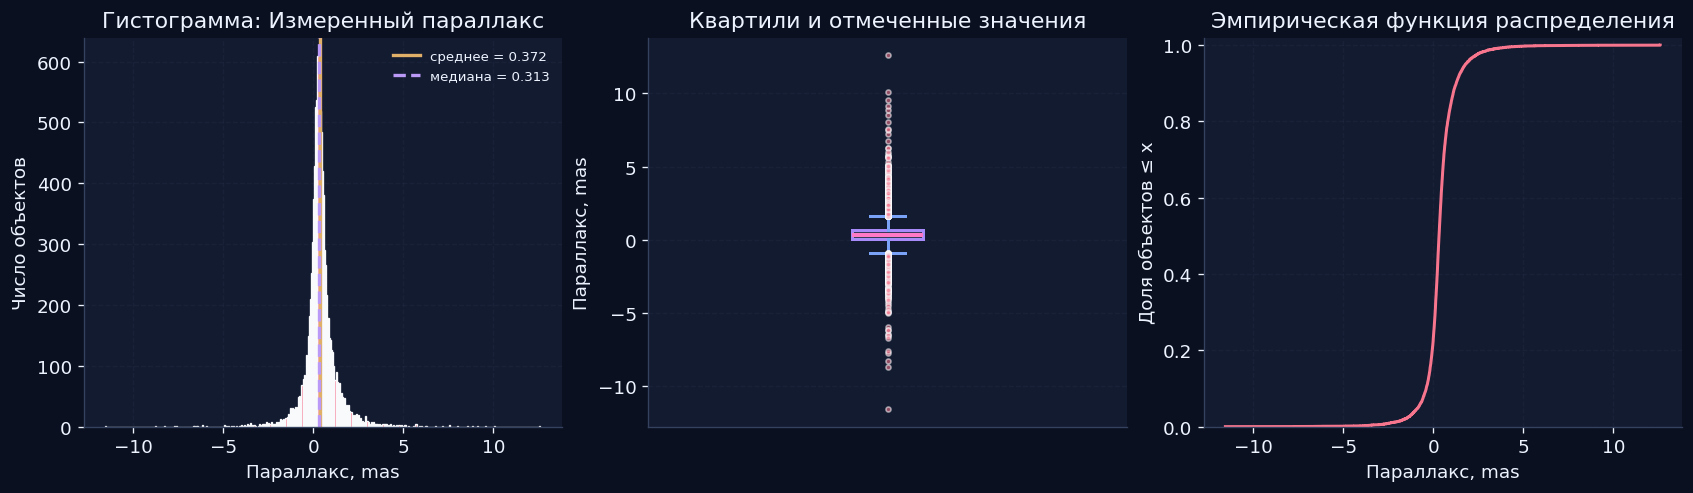

Показатель,Значение
min–max min,0.00000000
min–max max,1.00000000
Z среднее,0.00000000
Z s (N−1),1.00000000


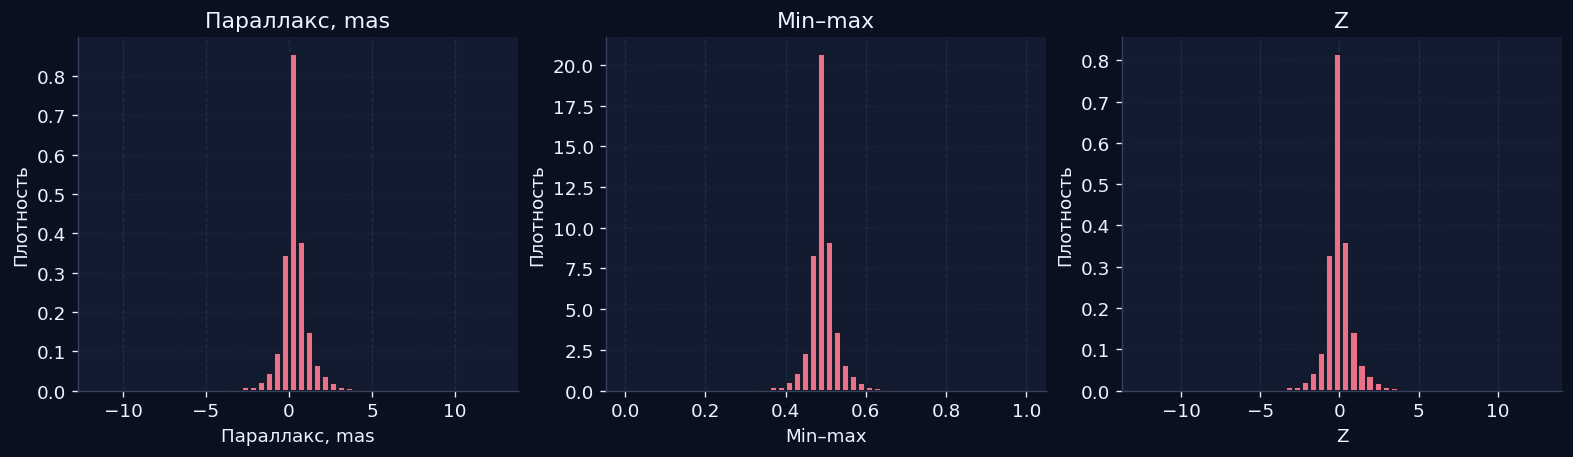

In [ ]:
# @title Описательная статистика: параллакс

from IPython.display import display, HTML

info = FEATURES[2]
a = df[info['column']].to_numpy(float)

summary_parallax, flags_parallax = describe_feature(
    a, info['unit'], info['label']
)
summary_parallax.to_csv(OUT / 'parallax_summary.csv', index=False)

display(
    summary_parallax.round(6).style
    .set_caption('Описательная статистика: параллакс')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

plot_eda(a, info, 'parallax')

display(HTML(f"""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по параллаксу
    </div>
    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">
        <b>Средний измеренный параллакс:</b> {a.mean():.4f} mas<br>
        <b>Медиана:</b> {np.median(a):.4f} mas<br>
        <b>Отрицательные измерения:</b> {int((a < 0).sum())}.
        Они не удаляются, поскольку это результат измерения с ошибкой,
        а не физическое отрицательное расстояние.
    </div>
</div>
"""))

scaled_parallax = scale_feature(a, info, 'parallax')

### Математическая модель параллакса

Параметрические распределения сравниваются на контрольной части данных. Из-за ошибок измерения и наблюдательного отбора форма параллакса может отличаться от простого симметричного колокола. Поэтому для практического генератора снова оставляем возможность использовать точную эмпирическую CDF рабочей базы.


Модель,"Обучение, n","Контроль, n",Параметров,AIC,BIC,KS D на контроле,p на контроле,Средний log-loss,p_Holm,"Решение при α=0,05"
Лапласа,7000,3000,2,15824.872421,15838.579752,0.075867,0.000000,1.102576,0.000000,Отвергаем H₀
Асимметричная нормальная,7000,3000,3,19131.300782,19151.861778,0.145473,0.000000,1.350804,0.000000,Отвергаем H₀
Нормальная,7000,3000,2,19308.240310,19321.947641,0.146829,0.000000,1.350654,0.000000,Отвергаем H₀


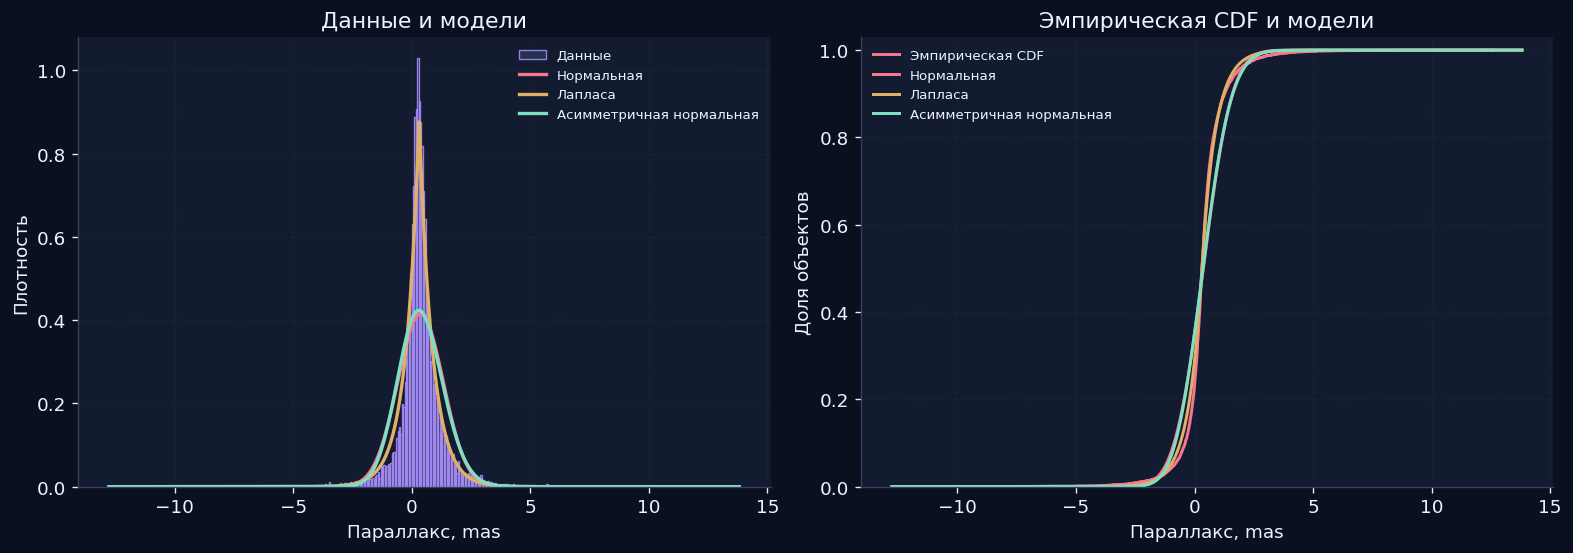

In [ ]:
# @title Модели распределения параллакса

from IPython.display import display, HTML

models_parallax, fitted_parallax, train_parallax, test_parallax = fit_models_train_test(
    a, 'Параллакс'
)

models_parallax.to_csv(
    OUT / 'parallax_distribution_models.csv',
    index=False
)

display(
    models_parallax.round(6).style
    .set_caption('Сравнение моделей распределения параллакса')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

plot_models(a, info, models_parallax, fitted_parallax, 'parallax')

display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по распределению параллакса
    </div>
    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">
        Измеренный параллакс нельзя автоматически заменять расстоянием.
        Для воспроизведения наблюдаемого распределения используем
        эмпирическую модель.
    </div>
</div>
"""))

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
6. Зависимость между тремя величинами
</h2></div>
"""))

<a id="dependence"></a>

Проверяем все три пары: `G`–`BP−RP`, `G`–параллакс и `BP−RP`–параллакс.

- Коэффициент Пирсона показывает линейную связь.
- Коэффициент Спирмена показывает монотонную связь и меньше зависит от формы распределения.
- Перестановочная проверка перемешивает одну колонку, сохраняя её одномерное распределение. Если наблюдаемая связь редко получается после перемешивания, независимость отвергается. *Перестановочная проверка независимости основана на логике permutation test [7].*

Нулевая гипотеза для каждой пары: **две характеристики независимы**. После трёх проверок применяется поправка Холма. Статистическая связь не доказывает причинность.


Пара,Pearson r,Pearson p,Spearman ρ,Spearman p,p перестановочный,p_Holm,Решение
G — BP−RP,0.112891,0.000000,0.143834,0.000000,0.000500,0.001500,Независимость отвергается
G — Параллакс,-0.127787,0.000000,-0.093355,0.000000,0.000500,0.001500,Независимость отвергается
BP−RP — Параллакс,0.104428,0.000000,0.128856,0.000000,0.000500,0.001500,Независимость отвергается


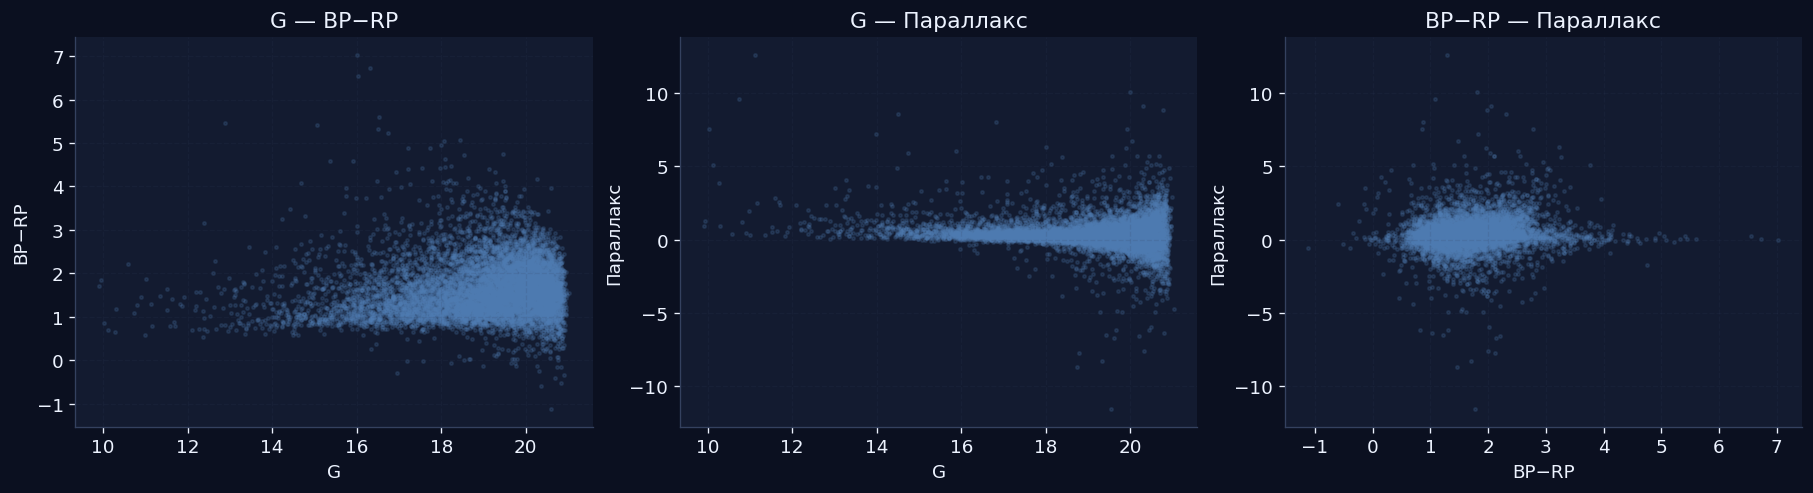

In [ ]:
# @title Анализ зависимости между признаками Gaia DR3

from IPython.display import display, HTML

# Pearson, Spearman и перестановочные p-value для всех трёх пар
pair_specs = [
    ('G', 'BP−RP'),
    ('G', 'Параллакс'),
    ('BP−RP', 'Параллакс')
]

arrays = {
    feature['key']: df[feature['column']].to_numpy(float)
    for feature in FEATURES
}

B_PERM = 1999
pair_rows = []

for pair_index, (left, right) in enumerate(pair_specs):
    x1, x2 = arrays[left], arrays[right]

    pear = stats.pearsonr(x1, x2)
    spear = stats.spearmanr(x1, x2)

    rng = np.random.default_rng(SEED + 2000 + pair_index)
    observed = abs(float(spear.statistic))
    exceed = 0

    # Перестановка рангов второй величины — тест независимости
    # для монотонной связи.
    r1 = stats.rankdata(x1)
    r2 = stats.rankdata(x2)

    for _ in range(B_PERM):
        perm = float(np.corrcoef(r1, rng.permutation(r2))[0, 1])
        exceed += abs(perm) >= observed

    pair_rows.append({
        'Пара': f'{left} — {right}',
        'Pearson r': pear.statistic,
        'Pearson p': pear.pvalue,
        'Spearman ρ': spear.statistic,
        'Spearman p': spear.pvalue,
        'p перестановочный': (exceed + 1) / (B_PERM + 1)
    })

dependence_table = pd.DataFrame(pair_rows)

dependence_table['p_Holm'] = holm_adjust(
    dependence_table['p перестановочный'].to_numpy()
)

dependence_table['Решение'] = np.where(
    dependence_table['p_Holm'] < ALPHA,
    'Независимость отвергается',
    'Недостаточно оснований отвергнуть независимость'
)

dependence_table.to_csv(
    OUT / 'dependence_all_pairs.csv',
    index=False
)

display(
    dependence_table.round(6).style
    .set_caption('Корреляции и тестирование зависимости между признаками')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center'),
                ('white-space', 'normal')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

# Диаграммы рассеяния для трёх пар признаков
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    constrained_layout=True
)

for ax, (left, right) in zip(axes, pair_specs):
    ax.scatter(
        arrays[left],
        arrays[right],
        s=4,
        alpha=0.18,
        color='#527fb5',
        rasterized=True
    )
    ax.set(
        xlabel=left,
        ylabel=right,
        title=f'{left} — {right}'
    )
    ax.grid(alpha=0.15)

fig.savefig(
    OUT / 'dependence_all_pairs.png',
    bbox_inches='tight'
)
plt.show()

display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по анализу зависимости
    </div>
    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">
        Если <b>p_Holm &lt; 0.05</b>, данные дают статистические основания
        считать пару зависимой. Если <b>p_Holm ≥ 0.05</b>, это только
        отсутствие обнаруженной связи, а не строгое доказательство
        независимости.
    </div>
</div>
"""))

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
7. Генеральная совокупность, выборки и состоятельность оценок
</h2></div>
"""))

<a id="sampling"></a>
В этой работе вся база из (N=10000) строк считается конечной генеральной совокупностью. Из неё строятся выборки:

- **с возвращением** — один и тот же объект может попасть несколько раз;
- **без возвращения** — внутри одной выборки повторов нет.

Для среднего теоретическая дисперсия имеет вид

$$
\operatorname{Var}_{WR}(\bar X_n)=\frac{v_N}{n},
\qquad
\operatorname{Var}_{WOR}(\bar X_n)=\frac{v_N}{n}\frac{N-n}{N-1}.
$$

*Формулы дисперсии среднего и поправки на конечную совокупность приведены по [8].*

Множитель ((N-n)/(N-1)) называется поправкой на конечную совокупность. Поэтому при выборке без возвращения разброс среднего уменьшается сильнее, а при (n=N) среднее восстанавливается точно.

Состоятельность проверяем эмпирически: при увеличении (n) считаем смещение и RMSE оценок среднего и дисперсии. Если RMSE уменьшается, оценка становится точнее.


In [ ]:
# @title Параметры конечной базы по всем трём величинам

from IPython.display import display

values = df[
    ['phot_g_mean_mag', 'bp_rp', 'parallax']
].to_numpy(float)

feature_keys = ['G', 'BP−RP', 'Параллакс']
feature_labels = ['G, mag', 'BP − RP, mag', 'Параллакс, mas']

population_rows = []

for j, key in enumerate(feature_keys):
    a = values[:, j]

    population_rows.append({
        'Характеристика': feature_labels[j],
        'N': N,
        'Среднее μ_N': a.mean(),
        'Дисперсия базы v_N': a.var(ddof=0),
        'Исправленная S²_N': a.var(ddof=1),
        's': a.std(ddof=1)
    })

population_table = pd.DataFrame(population_rows)

population_table.to_csv(
    OUT / 'population_parameters_all.csv',
    index=False
)

display(
    population_table.round(6).style
    .set_caption('Параметры конечной базы Gaia DR3')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

Характеристика,N,Среднее μ_N,Дисперсия базы v_N,Исправленная S²_N,s
"G, mag",10000,18.939417,2.472314,2.472561,1.572438
"BP − RP, mag",10000,1.620746,0.372466,0.372503,0.610331
"Параллакс, mas",10000,0.371944,0.907350,0.907441,0.952597


In [ ]:
# @title Пример двух выборок одинакового размера

from IPython.display import display

example_n = 500
example_rows = []

for mode, replace in [
    ('С возвращением', True),
    ('Без возвращения', False)
]:
    ids = np.random.default_rng(
        SEED + 300 + (1 if replace else 2)
    ).choice(N, example_n, replace=replace)

    row = {
        'Способ': mode,
        'n': example_n,
        'Уникальных объектов': len(np.unique(ids))
    }

    for j, key in enumerate(feature_keys):
        selected = values[ids, j]
        row[f'{feature_labels[j]}: среднее'] = selected.mean()
        row[f'{feature_labels[j]}: дисперсия'] = selected.var(ddof=1)

    example_rows.append(row)

examples_table = pd.DataFrame(example_rows)

examples_table.to_csv(
    OUT / 'sample_examples_all_features.csv',
    index=False
)

display(
    examples_table.round(6).style
    .set_caption('Сравнение выборок с возвращением и без возвращения')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center'),
                ('white-space', 'normal')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

Способ,n,Уникальных объектов,"G, mag: среднее","G, mag: дисперсия","BP − RP, mag: среднее","BP − RP, mag: дисперсия","Параллакс, mas: среднее","Параллакс, mas: дисперсия"
С возвращением,500,487,18.865693,2.426683,1.567963,0.318772,0.389170,0.600480
Без возвращения,500,500,18.901970,2.706435,1.608452,0.446855,0.334617,1.474435


Отбор,n,Характеристика,Смещение среднего,RMSE среднего,SD средних,Теоретическая SE,Смещение дисперсии,RMSE дисперсии
С возвращением,20,"G, mag",0.009250,0.346387,0.346842,0.351590,-0.010210,1.229154
С возвращением,20,"BP − RP, mag",0.011481,0.136252,0.135994,0.136467,0.010878,0.212134
С возвращением,20,"Параллакс, mas",-0.000092,0.206641,0.206986,0.212997,0.009644,0.868505
С возвращением,50,"G, mag",-0.006837,0.217357,0.217612,0.222365,0.061212,0.792877
С возвращением,50,"BP − RP, mag",-0.003163,0.090782,0.090878,0.086309,-0.012180,0.120589
С возвращением,50,"Параллакс, mas",-0.004841,0.135705,0.135845,0.134711,0.056736,0.619607
С возвращением,100,"G, mag",-0.011038,0.156015,0.155884,0.157236,0.023898,0.555403
С возвращением,100,"BP − RP, mag",0.000778,0.064358,0.064461,0.061030,0.004653,0.091471
С возвращением,100,"Параллакс, mas",0.001112,0.103690,0.103857,0.095255,0.018416,0.444043
С возвращением,500,"G, mag",0.009160,0.071798,0.071330,0.070318,-0.030839,0.239192


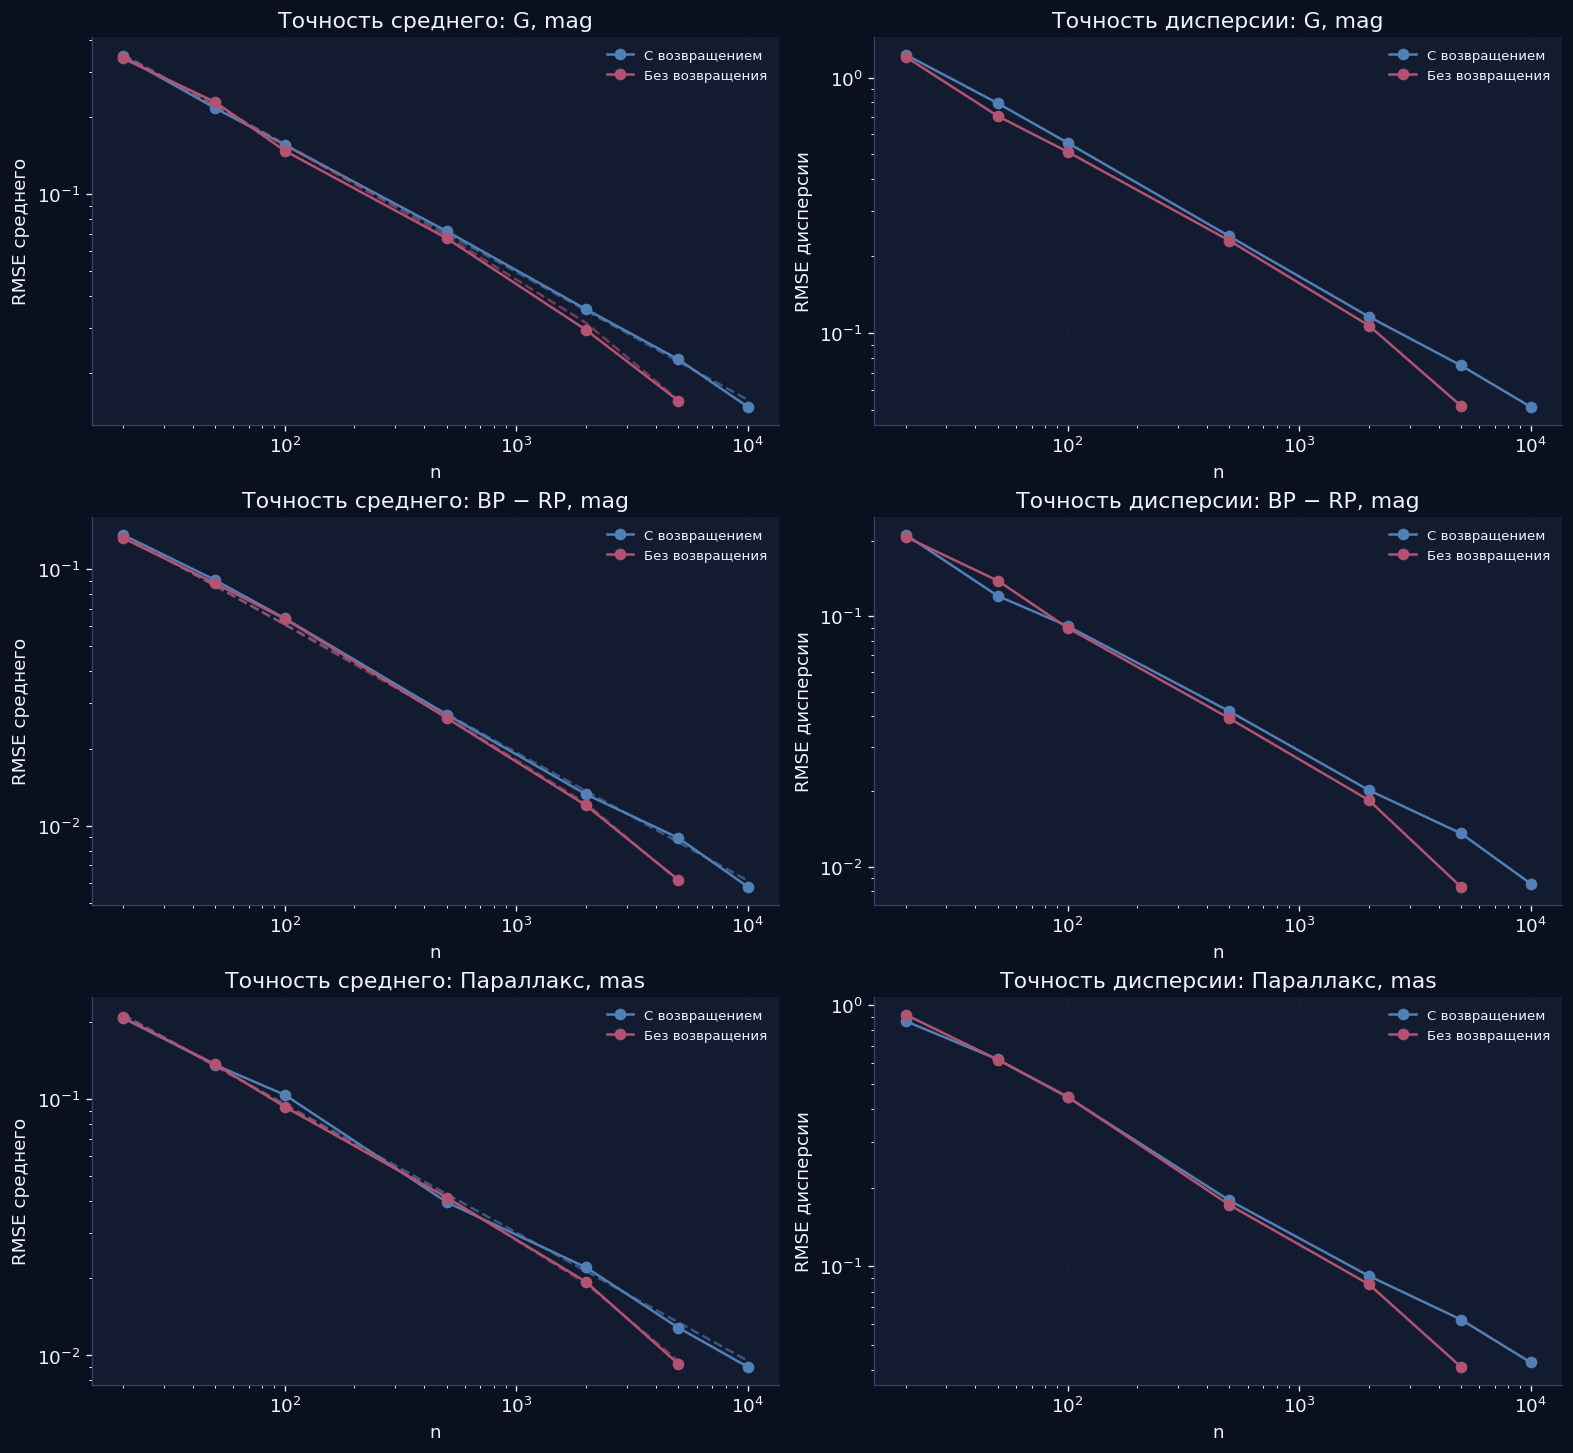

In [ ]:
# @title Повторные выборки: точность оценок для трёх величин

from IPython.display import display, HTML

sample_sizes = [20, 50, 100, 500, 2000, 5000, N]
REPEATS = 300
sampling_rows = []

rng = np.random.default_rng(SEED + 400)

for mode, replace in [
    ('С возвращением', True),
    ('Без возвращения', False)
]:
    for n in sample_sizes:
        mean_draws = np.empty((REPEATS, 3))
        var_draws = np.empty((REPEATS, 3))

        if not replace and n == N:
            mean_draws[:] = values.mean(axis=0)
            var_draws[:] = values.var(axis=0, ddof=1)
        else:
            for rep in range(REPEATS):
                idx = rng.choice(N, n, replace=replace)
                mean_draws[rep] = values[idx].mean(axis=0)
                var_draws[rep] = values[idx].var(axis=0, ddof=1)

        for j, key in enumerate(feature_keys):
            a = values[:, j]
            mu = a.mean()
            v = a.var(ddof=0)
            target = v if replace else a.var(ddof=1)

            finite_factor = 1.0 if replace else (N - n) / (N - 1)
            theory_se = np.sqrt(v / n * finite_factor)

            errors = mean_draws[:, j] - mu
            var_errors = var_draws[:, j] - target

            sampling_rows.append({
                'Отбор': mode,
                'n': n,
                'Характеристика': feature_labels[j],
                'R': REPEATS,
                'Смещение среднего': errors.mean(),
                'RMSE среднего': np.sqrt(np.mean(errors**2)),
                'SD средних': errors.std(ddof=1),
                'Теоретическая SE': theory_se,
                'Доля |ошибка среднего|>0.1': np.mean(
                    np.abs(errors) > 0.1
                    if key != 'Параллакс'
                    else np.abs(errors) > 0.1
                ),
                'Цель дисперсии': target,
                'Смещение дисперсии': var_errors.mean(),
                'RMSE дисперсии': np.sqrt(np.mean(var_errors**2))
            })

sampling_metrics = pd.DataFrame(sampling_rows)

sampling_metrics.to_csv(
    OUT / 'sampling_metrics_all_features.csv',
    index=False
)

display(
    sampling_metrics[
        [
            'Отбор',
            'n',
            'Характеристика',
            'Смещение среднего',
            'RMSE среднего',
            'SD средних',
            'Теоретическая SE',
            'Смещение дисперсии',
            'RMSE дисперсии'
        ]
    ].round(6).style
    .set_caption('Точность оценок при повторных выборках')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center'),
                ('white-space', 'normal')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

# Графики точности среднего и дисперсии
fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 12),
    constrained_layout=True
)

for j, key in enumerate(feature_keys):
    for mode, color in [
        ('С возвращением', '#527fb5'),
        ('Без возвращения', '#b25371')
    ]:
        part = sampling_metrics[
            (sampling_metrics['Характеристика'] == feature_labels[j])
            & (sampling_metrics['Отбор'] == mode)
        ]

        nz = part[part['RMSE среднего'] > 0]

        axes[j, 0].plot(
            nz['n'],
            nz['RMSE среднего'],
            'o-',
            color=color,
            label=mode
        )
        axes[j, 0].plot(
            nz['n'],
            nz['Теоретическая SE'],
            '--',
            color=color,
            alpha=0.6
        )

        nzv = part[part['RMSE дисперсии'] > 0]

        axes[j, 1].plot(
            nzv['n'],
            nzv['RMSE дисперсии'],
            'o-',
            color=color,
            label=mode
        )

    axes[j, 0].set(
        xscale='log',
        yscale='log',
        xlabel='n',
        ylabel='RMSE среднего',
        title=f'Точность среднего: {feature_labels[j]}'
    )

    axes[j, 1].set(
        xscale='log',
        yscale='log',
        xlabel='n',
        ylabel='RMSE дисперсии',
        title=f'Точность дисперсии: {feature_labels[j]}'
    )

    for ax in axes[j]:
        ax.grid(alpha=0.15)
        ax.legend(frameon=False, fontsize=8)

fig.savefig(
    OUT / 'sampling_precision_all_features.png',
    bbox_inches='tight'
)
plt.show()

display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по повторным выборкам
    </div>
    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">
        При увеличении размера выборки RMSE среднего и дисперсии
        в целом уменьшается. Без возвращения разброс среднего
        дополнительно уменьшается из-за поправки на конечную совокупность.
    </div>
</div>
"""))

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
8. Проверка статистических гипотез
</h2></div>
"""))

<a id="hypotheses"></a>

В работе используются следующие нулевые гипотезы:

1. для каждой пары характеристик значения независимы;
2. среднее значение характеристики у 500 самых ярких объектов такое же, как у обычной случайной выборки из 500 объектов.

Уровень значимости везде (α=0.05). Если p-value меньше 0.05, нулевая гипотеза отвергается. Это не доказывает физическую причинность: тест показывает только статистическую несовместимость с выбранной нулевой моделью.


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
9. Эксперимент: что меняется при выборе самых ярких объектов
</h2></div>
"""))

<a id="selection"></a>

Объекты с наименьшими `G` — самые яркие. Берём 500 таких объектов и сравниваем их с 1999 равновероятными выборками по 500 строк без возвращения.

Если среднее цвета или параллакса у яркой группы выходит за обычный диапазон случайных средних, это показывает, что отбор по яркости меняет состав группы. Проверяем это перестановочным методом и применяем поправку Холма к двум проверкам.


Характеристика,Среднее базы,Среднее ярких 500,Разность,Сдвиг / σ базы,95% случайных средних: низ,95% случайных средних: верх,p_MC,p_Holm,Решение
"G, mag",18.939417,14.565663,-4.373754,-2.78165,18.799345,19.067568,nan,nan,Контроль отбора
"BP − RP, mag",1.620746,1.367696,-0.25305,-0.414632,1.572025,1.672904,0.0005,0.001,Отличается от случайной выборки
"Параллакс, mas",0.371944,0.870217,0.498273,0.523094,0.291434,0.449934,0.0005,0.001,Отличается от случайной выборки


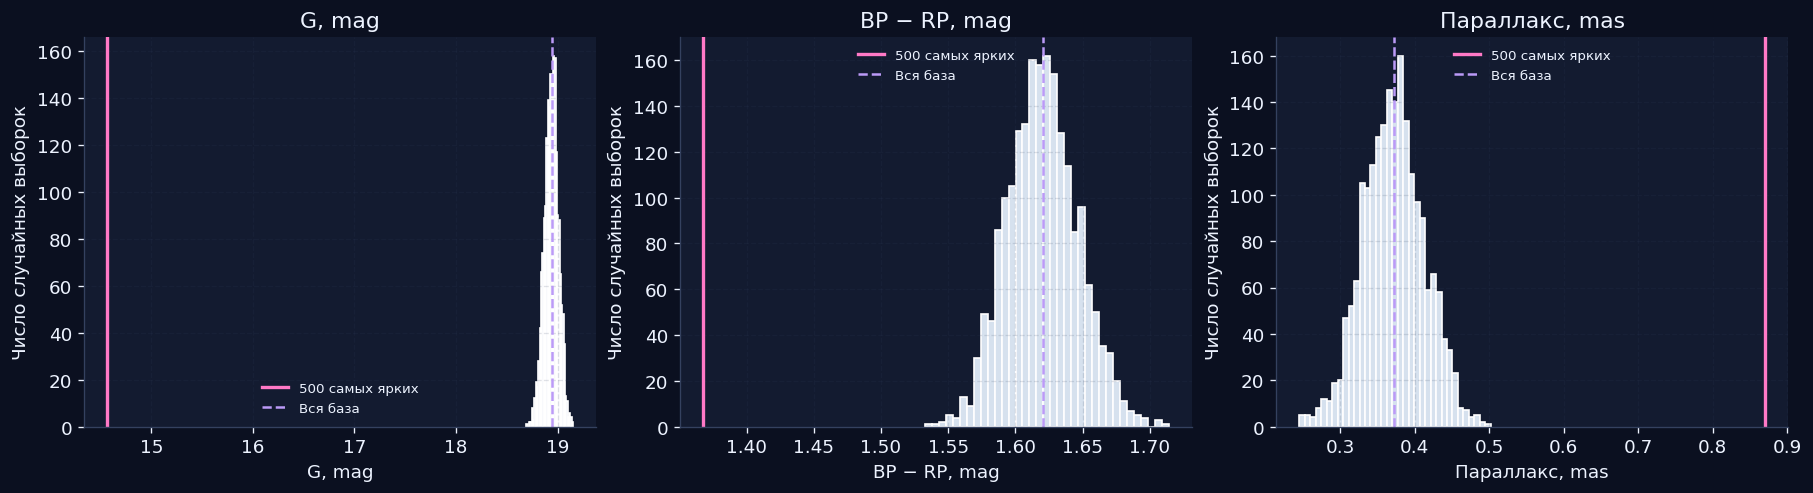

In [ ]:

# @title Яркостный отбор: сравнение со случайными выборками

BRIGHT_N = 500
SELECTION_REPEATS = 1999

bright_indices = np.argsort(values[:, 0], kind='stable')[:BRIGHT_N]
bright_values = values[bright_indices]

pop_means = values.mean(axis=0)
pop_stds = values.std(axis=0, ddof=0)

rng = np.random.default_rng(SEED + 500)
random_means = np.empty((SELECTION_REPEATS, 3))
random_medians = np.empty_like(random_means)
random_stds = np.empty_like(random_means)

for rep in range(SELECTION_REPEATS):
    idx = rng.choice(N, BRIGHT_N, replace=False)
    selected = values[idx]

    random_means[rep] = selected.mean(axis=0)
    random_medians[rep] = np.median(selected, axis=0)
    random_stds[rep] = selected.std(axis=0, ddof=1)

observed = np.abs(bright_values.mean(axis=0) - pop_means)

raw_p = []
for j in [1, 2]:
    raw_p.append(
        (1 + np.sum(
            np.abs(random_means[:, j] - pop_means[j]) >= observed[j]
        )) / (SELECTION_REPEATS + 1)
    )

holm_p = holm_adjust(raw_p)

selection_rows = []

for j, key in enumerate(feature_keys):
    low, high = np.quantile(random_means[:, j], [0.025, 0.975])

    selection_rows.append({
        'Характеристика': feature_labels[j],
        'Среднее базы': pop_means[j],
        'Среднее ярких 500': bright_values[:, j].mean(),
        'Разность': bright_values[:, j].mean() - pop_means[j],
        'Сдвиг / σ базы': (
            bright_values[:, j].mean() - pop_means[j]
        ) / pop_stds[j],
        '95% случайных средних: низ': low,
        '95% случайных средних: верх': high,
        'p_MC': np.nan if j == 0 else raw_p[j - 1],
        'p_Holm': np.nan if j == 0 else holm_p[j - 1],
        'Решение': (
            'Контроль отбора' if j == 0 else
            ('Отличается от случайной выборки'
             if holm_p[j - 1] < ALPHA
             else 'Недостаточно оснований для отличия')
        )
    })

selection_table = pd.DataFrame(selection_rows)

selection_table.to_csv(
    OUT / 'bright_selection_all_features.csv',
    index=False
)


# Отображение таблицы в HTML-стиле
from IPython.display import display, HTML
import html

df = selection_table.round(6)

headers = ''.join(
    f'<th style="padding:14px;text-align:left;white-space:nowrap;">'
    f'{html.escape(str(col))}</th>'
    for col in df.columns
)

rows = ''

for i, row in enumerate(df.itertuples(index=False, name=None)):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'

    cells = ''.join(
        '<td style="padding:12px;border-bottom:1px solid #E5E7EB;'
        'white-space:nowrap;">'
        f'{html.escape(str(value))}</td>'
        for value in row
    )

    rows += f'<tr style="background:{bg};">{cells}</tr>'

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Результаты яркостного отбора
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          {headers}
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))


# Порог яркой группы
threshold = values[bright_indices, 0].max()

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;
            border:1px solid #D8D4F0;border-radius:10px;overflow:hidden;">
  <div style="background:#111827;color:#F8FAFC;padding:12px 16px;
              font-size:15px;font-weight:bold;">
    Критерий отбора
  </div>
  <div style="background:#F5F3FF;padding:14px 16px;color:#1F2937;
              font-size:14px;line-height:1.6;">
    Выбрано <b>{BRIGHT_N}</b> самых ярких объектов.<br>
    Порог яркости: <b>G ≤ {threshold:.4f} mag</b>.
    Чем меньше звёздная величина G, тем ярче объект.
  </div>
</div>
"""))


# Графики распределений средних случайных выборок
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    constrained_layout=True
)

for j, key in enumerate(feature_keys):
    axes[j].hist(
        random_means[:, j],
        bins=35,
        color='#d6e1ee',
        edgecolor='white'
    )

    axes[j].axvline(
        bright_values[:, j].mean(),
        color=COLORS['bright'],
        lw=2,
        label='500 самых ярких'
    )

    axes[j].axvline(
        pop_means[j],
        color=COLORS['median'],
        ls='--',
        label='Вся база'
    )

    axes[j].set(
        xlabel=feature_labels[j],
        ylabel='Число случайных выборок',
        title=feature_labels[j]
    )

    axes[j].legend(frameon=False, fontsize=8)
    axes[j].grid(alpha=.15)

fig.savefig(
    OUT / 'bright_selection_all_features.png',
    bbox_inches='tight'
)
plt.show()


# Итоговый вывод
display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    margin: 20px 0;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    color: #1F2937;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 14px 18px;
        font-size: 16px;
        font-weight: bold;
    ">
        Вывод
    </div>
    <div style="
        background: #F5F3FF;
        padding: 16px 18px;
        font-size: 14px;
        line-height: 1.7;
    ">
        Яркостный отбор меняет средний цвет и/или параллакс
        по сравнению со случайным отбором.
    </div>
</div>
"""))


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
10. Зачем нужен генератор
</h2></div>
"""))

<a id="sprint2"></a>

Генератор должен создавать значения, похожие на наблюдаемые значения одной характеристики. В основной части строим генератор для `G`, а затем проверяем тот же алгоритм отдельно на цвете и параллаксе.

Важно различать две вещи:

- `PCG64` в NumPy — базовый генератор равномерных псевдослучайных чисел;
- наш алгоритм — преобразование равномерного числа в значение нужной случайной величины.

Мы не выдаём сгенерированные строки за новые реальные звёзды. Генератор воспроизводит одномерные распределения рабочей базы. Если генерировать три столбца независимо, исходные зависимости между ними потеряются.


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
11. Математическое описание алгоритмов
</h2></div>
"""))

<a id="algorithms"></a>

*Математические принципы обратного метода, суперпозиции и метода Неймана описаны у Devroye [4].*

### Метод обратной функции

Пусть $$U\sim U(0,1)$$ а (F) — функция распределения. Тогда

$$
X=F^{-1}(U),
\qquad
F^{-1}(u)=\inf\{x:F(x)\ge u\}.
$$

Поскольку $$P(F^{-1}(U)\le x)=P(U\le F(x))=F(x)$$, полученное значение имеет нужное распределение. Для эмпирической базы сортируем наблюдения и выбираем одну из позиций с вероятностью (1/N).

### Метод суперпозиции

Если $$F(x)=\sum_jw_jF_j(x)$$, сначала выбираем компонент (j) с вероятностью (w_j), затем генерируем значение из (F_j). В работе базу делим по медиане `G`; это техническое разбиение, а не утверждение о существовании двух физических классов звёзд. Веса компонентов равны размерам частей, поэтому вероятность каждой исходной строки остаётся (1/N).

### Обзор дополнительных методов

| Метод | Где применяется | Сильная сторона | Ограничение |
|---|---|---|---|
| Обратная CDF | дискретные и непрерывные распределения с доступной CDF | простое доказательство | обратная функция может быть сложной |
| Суперпозиция | смеси распределений | удобно для неоднородных данных | нужны корректные веса |
| Нейман, принятие–отклонение | сложные плотности при известной огибающей | не требуется обратная CDF | бывают отказы, нужно доказать границу |
| Ratio of uniforms | непрерывные плотности | универсальный геометрический метод | нужны конечные границы области |

Два первых метода реализованы для эмпирического распределения `G`. Два последних приведены и реализованы как учебный пример генерации (N(0,1)); они не подменяют основной эмпирический генератор.


Характеристика,Метод,n,Среднее базы,Среднее генератора,Медиана базы,Медиана генератора,s базы,s генератора,Q1 базы,Q1 генератора,Q3 базы,Q3 генератора,KS D,Wasserstein
"G, mag",Обратная CDF,10000,18.939417,18.935993,19.339181,19.34957,1.572438,1.574655,18.189339,18.163492,20.104594,20.11565,0.005,0.011401
"G, mag",Суперпозиция,10000,18.939417,18.943653,19.339181,19.336058,1.572438,1.550561,18.189339,18.206399,20.104594,20.086812,0.0091,0.016235
"BP − RP, mag",Обратная CDF,10000,1.620746,1.62293,1.530344,1.537374,0.610331,0.600385,1.190716,1.199891,1.952171,1.951023,0.0099,0.009073
"BP − RP, mag",Суперпозиция,10000,1.620746,1.621865,1.530344,1.527388,0.610331,0.619946,1.190716,1.18774,1.952171,1.946944,0.0064,0.006908
"Параллакс, mas",Обратная CDF,10000,0.371944,0.377237,0.312884,0.310185,0.952597,0.937356,0.024495,0.025753,0.662262,0.667872,0.0064,0.016696
"Параллакс, mas",Суперпозиция,10000,0.371944,0.378518,0.312884,0.30495,0.952597,0.932074,0.024495,0.023768,0.662262,0.661325,0.0082,0.012632


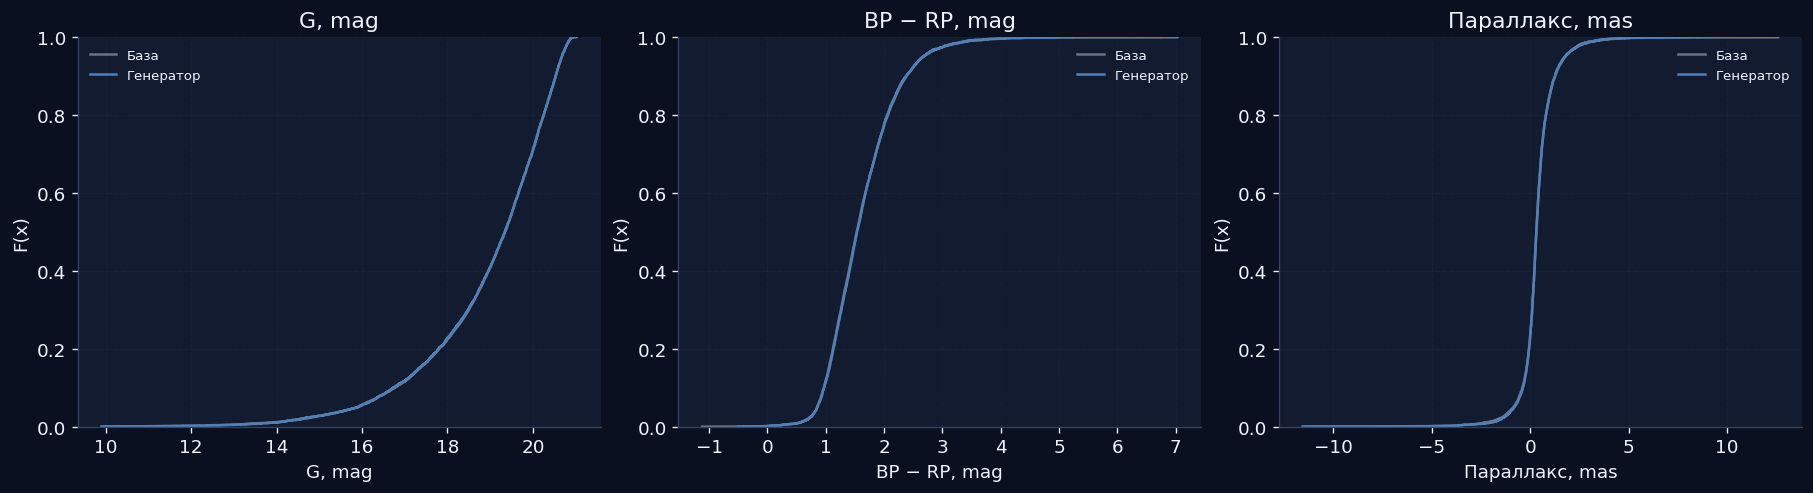

In [ ]:

# @title Два генератора по эмпирическому распределению

def validate_input(values, size):
    a = np.asarray(values, dtype=float)
    if a.ndim != 1 or a.size == 0 or not np.isfinite(a).all():
        raise ValueError('values должен быть непустым одномерным массивом конечных чисел')
    if isinstance(size, (bool, np.bool_)) or not isinstance(size, (int, np.integer)) or size < 0:
        raise ValueError('size должен быть неотрицательным целым числом')
    return a


def empirical_inverse_sample(values, size, rng):
    a = validate_input(values, size)
    ordered = np.sort(a)
    positions = np.floor(rng.random(size) * len(ordered)).astype(np.int64)
    return ordered[positions]


def empirical_superposition_sample(values, size, rng):
    a = validate_input(values, size)
    pivot = np.median(a)
    left = a[a <= pivot]
    right = a[a > pivot]

    if len(right) == 0:
        return empirical_inverse_sample(left, size, rng)

    choose_right = rng.random(size) >= len(left) / len(a)
    result = np.empty(size, dtype=float)
    result[~choose_right] = empirical_inverse_sample(
        left, int((~choose_right).sum()), rng
    )
    result[choose_right] = empirical_inverse_sample(
        right, int(choose_right.sum()), rng
    )
    return result


generator_rows = []
generated_by_method = {}

for feature_index, (key, label) in enumerate(zip(feature_keys, feature_labels)):
    source = values[:, feature_index]

    for method_index, (method_name, method) in enumerate([
        ('Обратная CDF', empirical_inverse_sample),
        ('Суперпозиция', empirical_superposition_sample)
    ]):
        generated = method(
            source,
            10000,
            np.random.default_rng(SEED + 700 + feature_index * 10 + method_index)
        )
        generated_by_method[(key, method_name)] = generated

        generator_rows.append({
            'Характеристика': label,
            'Метод': method_name,
            'n': len(generated),
            'Среднее базы': source.mean(),
            'Среднее генератора': generated.mean(),
            'Медиана базы': np.median(source),
            'Медиана генератора': np.median(generated),
            's базы': source.std(ddof=1),
            's генератора': generated.std(ddof=1),
            'Q1 базы': np.quantile(source, .25),
            'Q1 генератора': np.quantile(generated, .25),
            'Q3 базы': np.quantile(source, .75),
            'Q3 генератора': np.quantile(generated, .75),
            'KS D': stats.ks_2samp(source, generated).statistic,
            'Wasserstein': stats.wasserstein_distance(source, generated)
        })

generator_comparison = pd.DataFrame(generator_rows)

generator_comparison.to_csv(
    OUT / 'generator_comparison_all_features.csv',
    index=False
)


# Отображение таблицы в HTML-стиле
from IPython.display import display, HTML
import html

df = generator_comparison.round(6)

headers = ''.join(
    f'<th style="padding:14px;text-align:left;white-space:nowrap;">'
    f'{html.escape(str(col))}</th>'
    for col in df.columns
)

rows = ''

for i, row in enumerate(df.itertuples(index=False, name=None)):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'
    cells = ''.join(
        '<td style="padding:12px;border-bottom:1px solid #E5E7EB;'
        'white-space:nowrap;">'
        f'{html.escape(str(value))}</td>'
        for value in row
    )
    rows += f'<tr style="background:{bg};">{cells}</tr>'

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Сравнение эмпирических генераторов
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          {headers}
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))


# Главный генератор G и его распределение
main_generated = generated_by_method[('G', 'Обратная CDF')]

pd.DataFrame({
    'G_generated': main_generated
}).to_csv(OUT / 'generated_G.csv', index=False)


# Сравнение эмпирических функций распределения
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

for j, key in enumerate(feature_keys):
    source = values[:, j]
    gen = generated_by_method[(key, 'Обратная CDF')]

    axes[j].step(
        np.sort(source),
        np.arange(1, N + 1) / N,
        where='post',
        label='База',
        color='#697586'
    )
    axes[j].step(
        np.sort(gen),
        np.arange(1, len(gen) + 1) / len(gen),
        where='post',
        label='Генератор',
        color='#527fb5'
    )
    axes[j].set(
        xlabel=feature_labels[j],
        ylabel='F(x)',
        title=feature_labels[j],
        ylim=(0, 1)
    )
    axes[j].legend(frameon=False, fontsize=8)
    axes[j].grid(alpha=.15)

fig.savefig(
    OUT / 'generator_cdf_comparison_all_features.png',
    bbox_inches='tight'
)
plt.show()

from IPython.display import display, HTML

display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    margin: 20px 0;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    color: #1F2937;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 14px 18px;
        font-size: 16px;
        font-weight: bold;
    ">
        Вывод
    </div>

    <div style="
        background: #F5F3FF;
        padding: 16px 18px;
        font-size: 14px;
        line-height: 1.7;
    ">
        <p>
        Обе реализации воспроизводят одномерные эмпирические распределения. Это воспроизведение конечной базы, а не прогноз свойств неизвестной звезды.
        </p>

    </div>
</div>
"""))



[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
12. Автоматические проверки генераторов
</h2></div>
"""))

<a id="tests"></a>

Проверяем не только один удачный запуск, а свойства функций:

1. правильный размер результата;
2. воспроизводимость при одинаковом seed;
3. пустой результат при размере 0;
4. работа с базой из одного значения;
5. принадлежность результатов исходной базе;
6. сохранение вероятностей повторяющихся значений;
7. отклонение пустых и некорректных входных данных.


In [ ]:

# @title

class GeneratorTests(unittest.TestCase):
    methods = (empirical_inverse_sample, empirical_superposition_sample)

    def test_size(self):
        for method in self.methods:
            self.assertEqual(
                method([1., 2., 5.], 123, np.random.default_rng(1)).shape,
                (123,)
            )

    def test_reproducibility(self):
        for method in self.methods:
            a = method([1., 2., 5.], 1000, np.random.default_rng(15))
            b = method([1., 2., 5.], 1000, np.random.default_rng(15))
            np.testing.assert_array_equal(a, b)

    def test_empty(self):
        for method in self.methods:
            self.assertEqual(
                method([1., 2.], 0, np.random.default_rng(1)).shape,
                (0,)
            )

    def test_singleton(self):
        for method in self.methods:
            np.testing.assert_array_equal(
                method([7.], 100, np.random.default_rng(2)),
                np.full(100, 7.)
            )

    def test_support(self):
        for method in self.methods:
            d = method([-3., 1., 1., 9.], 5000, np.random.default_rng(11))
            self.assertTrue(
                np.isfinite(d).all() and np.isin(d, [-3., 1., 9.]).all()
            )

    def test_duplicate_weights(self):
        for method in self.methods:
            d = method([1., 1., 3.], 60000, np.random.default_rng(31))
            self.assertLess(
                abs(np.mean(d == 3) - 1/3),
                6 * np.sqrt((1/3) * (2/3) / 60000)
            )

    def test_invalid(self):
        for method in self.methods:
            for values_bad in [[], [[1., 2.]], [np.nan], [np.inf], 5.]:
                with self.assertRaises(ValueError):
                    method(values_bad, 1, np.random.default_rng(4))

            for size_bad in [-1, 1.5, True]:
                with self.assertRaises(ValueError):
                    method([1., 2.], size_bad, np.random.default_rng(4))


suite = unittest.defaultTestLoader.loadTestsFromTestCase(GeneratorTests)
result = unittest.TestResult()
suite.run(result)

if not result.wasSuccessful():
    raise AssertionError(result.errors + result.failures)

test_results = pd.DataFrame({
    'Проверка': [
        'Размер',
        'Воспроизводимость',
        'Нулевой размер',
        'Одна точка',
        'Диапазон исходной базы',
        'Повторяющиеся значения',
        'Ошибочные аргументы'
    ],
    'Результат': ['Пройдена'] * 7
})

test_results.to_csv(OUT / 'generator_tests.csv', index=False)

# Отображение в едином HTML-стиле
from IPython.display import display, HTML
import html

headers = ''.join(
    f'<th style="padding:14px;text-align:left;">'
    f'{html.escape(str(col))}</th>'
    for col in test_results.columns
)

rows = ''
for i, row in enumerate(test_results.itertuples(index=False, name=None)):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'
    cells = ''.join(
        '<td style="padding:12px;border-bottom:1px solid #E5E7EB;">'
        f'{html.escape(str(value))}</td>'
        for value in row
    )
    rows += f'<tr style="background:{bg};">{cells}</tr>'

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Результаты автотестов генераторов
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          {headers}
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))

print('Пройдено проверок:', result.testsRun)


Проверка,Результат
Размер,Пройдена
Воспроизводимость,Пройдена
Нулевой размер,Пройдена
Одна точка,Пройдена
Диапазон исходной базы,Пройдена
Повторяющиеся значения,Пройдена
Ошибочные аргументы,Пройдена


Пройдено проверок: 7


### Учебные реализации двух дополнительных алгоритмов

Метод Неймана генерирует кандидата из простой плотности и принимает его с вероятностью, зависящей от отношения целевой плотности к огибающей. Метод отношений равномерных величин строит точку в специальной области и возвращает отношение координат. Оба метода используют равномерные числа PCG64 и служат примером алгоритмов для (N(0,1)), а не генератора Gaia.


In [ ]:
# @title

def rejection_normal(size, seed):
    rng = np.random.default_rng(seed)
    out = []
    proposed = accepted = 0

    while sum(len(part) for part in out) < size:
        y = rng.laplace(size=4096)
        u = rng.random(4096)
        ok = u <= np.exp(-0.5 * (np.abs(y) - 1)**2)

        proposed += len(y)
        accepted += int(ok.sum())
        out.append(y[ok])

    return np.concatenate(out)[:size], accepted / proposed


def ratio_uniforms_normal(size, seed):
    rng = np.random.default_rng(seed)
    out = []
    proposed = accepted = 0

    vmax = np.sqrt(2 / np.e)

    while sum(len(part) for part in out) < size:
        u = np.maximum(
            rng.random(4096),
            np.nextafter(0., 1.)
        )
        v = rng.uniform(-vmax, vmax, 4096)
        y = v / u
        ok = 2 * np.log(u) <= -0.5 * y * y

        proposed += len(u)
        accepted += int(ok.sum())
        out.append(y[ok])

    return np.concatenate(out)[:size], accepted / proposed


demos = []

for name, fn, seed in [
    ('Нейман', rejection_normal, SEED + 900),
    ('Ratio of uniforms', ratio_uniforms_normal, SEED + 901)
]:
    generated, acceptance = fn(10000, seed)

    demos.append({
        'Метод': name,
        'Среднее': generated.mean(),
        's': generated.std(ddof=1),
        'KS D к N(0,1)': stats.kstest(generated, 'norm').statistic,
        'Доля принятых': acceptance
    })


algorithm_demos = pd.DataFrame(demos)

algorithm_demos.to_csv(
    OUT / 'additional_algorithm_demonstrations.csv',
    index=False
)


# Оформленная таблица результатов
from IPython.display import display, HTML
import html

df = algorithm_demos.round(6)

headers = ''.join(
    f'<th style="padding:14px;text-align:left;white-space:nowrap;">'
    f'{html.escape(str(col))}</th>'
    for col in df.columns
)

rows = ''

for i, row in enumerate(df.itertuples(index=False, name=None)):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'

    cells = ''.join(
        '<td style="padding:12px;border-bottom:1px solid #E5E7EB;">'
        f'{html.escape(str(value))}</td>'
        for value in row
    )

    rows += f'<tr style="background:{bg};">{cells}</tr>'

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Сравнение алгоритмов генерации стандартной нормали
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          {headers}
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))


Метод,Среднее,s,"KS D к N(0,1)",Доля принятых
Нейман,-0.01367,1.011932,0.011218,0.765625
Ratio of uniforms,-0.008538,1.000381,0.006128,0.729187


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
13. Итоговые выводы
</h2></div>
"""))

<a id="conclusions"></a>
1. Мы рассматривали не абстрактные числа, а характеристики случайно выбранного объекта Gaia. Поэтому `G`, `BP − RP` и измеренный параллакс являются случайными величинами в рамках заданного опыта.
2. У трёх величин разные единицы, центры и разбросы. Min–max и стандартизация помогают сравнить масштабы, но сами по себе не превращают данные в нормальные.
3. Параметрические модели проверялись на контрольных данных. Даже если одна модель имеет меньший BIC, это не означает, что она точно описывает каталог. Для конечной базы самым честным описанием является эмпирическое распределение.
4. При увеличении объёма случайной выборки RMSE среднего и дисперсии уменьшается. Для выборки без возвращения разброс среднего дополнительно уменьшается из-за поправки на конечную совокупность.
5. Связи между характеристиками проверялись для всех трёх пар. Статистически значимая связь означает, что совместное распределение отличается от независимого, но не объясняет физическую причину.
6. Выбор 500 самых ярких объектов меняет состав группы. Поэтому средние цвета и параллакса такой группы нельзя автоматически считать характеристиками всей базы.
7. Эмпирические генераторы воспроизводят одномерные распределения наблюдаемых величин и проходят автоматические проверки. При независимой генерации трёх столбцов их исходные связи теряются; для искусственных физически согласованных звёзд нужна совместная модель.
8. Выводы относятся к рабочей базе Gaia DR3. В них не учитывается полная селекция каталога, пространственная структура, ошибки всех измерений и принадлежность каждого объекта к классу «звезда».

Следующая кодовая ячейка печатает те же выводы с фактическими числами из текущего запуска.


In [ ]:
# @title

from IPython.display import display, HTML
import pandas as pd
import numpy as np
import html

# Единый стиль таблиц
def styled_html_table(df, title, digits=6):
    df = df.copy()

    def format_value(value):
        if pd.isna(value):
            return "NaN"

        if isinstance(value, (int, np.integer)):
            return str(value)

        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}"

        return str(value)

    headers = "".join(
        f'<th style="padding:14px;text-align:left;'
        f'white-space:nowrap;">{html.escape(str(col))}</th>'
        for col in df.columns
    )

    rows = []
    for i, row in enumerate(df.itertuples(index=False, name=None)):
        background = "#F5F3FF" if i % 2 == 0 else "#FFFFFF"

        cells = "".join(
            '<td style="padding:12px;'
            'border-bottom:1px solid #E5E7EB;">'
            f'{html.escape(format_value(value))}</td>'
            for value in row
        )

        rows.append(
            f'<tr style="background:{background};">{cells}</tr>'
        )

    display(HTML(f"""
    <div style="font-family:Arial,sans-serif;margin:16px 0;">
      <div style="font-size:16px;font-weight:bold;color:#111827;
                  margin:0 0 10px 0;">
        {html.escape(title)}
      </div>
      <div style="overflow-x:auto;border:1px solid #D8D4F0;
                  border-radius:10px;">
        <table style="width:100%;border-collapse:separate;
                      border-spacing:0;font-size:14px;
                      color:#1F2937;">
          <thead>
            <tr style="background:#111827;color:#F8FAFC;">
              {headers}
            </tr>
          </thead>
          <tbody>
            {''.join(rows)}
          </tbody>
        </table>
      </div>
    </div>
    """))


# 1. ЧИСЛЕННЫЙ ИТОГ
summary_rows = []

for j, key in enumerate(feature_keys):
    a = values[:, j]

    summary_rows.append({
        "Характеристика": feature_labels[j],
        "N": N,
        "Среднее": a.mean(),
        "Медиана": np.median(a),
        "s": a.std(ddof=1),
        "Дисперсия": a.var(ddof=1)
    })

styled_html_table(
    pd.DataFrame(summary_rows),
    "ЧИСЛЕННЫЙ ИТОГ"
)


# 2. Зависимости
styled_html_table(
    dependence_table[
        ["Пара", "Spearman ρ", "p_Holm", "Решение"]
    ].round(6),
    "Зависимости"
)


# 3. Яркостный отбор
styled_html_table(
    selection_table[
        [
            "Характеристика",
            "Среднее базы",
            "Среднее ярких 500",
            "Разность",
            "p_Holm",
            "Решение"
        ]
    ].round(6),
    "Яркостный отбор"
)


# 4. Сравнение генераторов
styled_html_table(
    generator_comparison[
        [
            "Характеристика",
            "Метод",
            "Среднее базы",
            "Среднее генератора",
            "KS D",
            "Wasserstein"
        ]
    ].round(6),
    "Генератор"
)


Характеристика,N,Среднее,Медиана,s,Дисперсия
"G, mag",10000,18.939417,19.339181,1.572438,2.472561
"BP − RP, mag",10000,1.620746,1.530344,0.610331,0.372503
"Параллакс, mas",10000,0.371944,0.312884,0.952597,0.907441


Пара,Spearman ρ,p_Holm,Решение
G — BP−RP,0.143834,0.001500,Независимость отвергается
G — Параллакс,-0.093355,0.001500,Независимость отвергается
BP−RP — Параллакс,0.128856,0.001500,Независимость отвергается


Характеристика,Среднее базы,Среднее ярких 500,Разность,p_Holm,Решение
"G, mag",18.939417,14.565663,-4.373754,NaN,Контроль отбора
"BP − RP, mag",1.620746,1.367696,-0.253050,0.001000,Отличается от случайной выборки
"Параллакс, mas",0.371944,0.870217,0.498273,0.001000,Отличается от случайной выборки


Характеристика,Метод,Среднее базы,Среднее генератора,KS D,Wasserstein
"G, mag",Обратная CDF,18.939417,18.935993,0.005000,0.011401
"G, mag",Суперпозиция,18.939417,18.943653,0.009100,0.016235
"BP − RP, mag",Обратная CDF,1.620746,1.622930,0.009900,0.009073
"BP − RP, mag",Суперпозиция,1.620746,1.621865,0.006400,0.006908
"Параллакс, mas",Обратная CDF,0.371944,0.377237,0.006400,0.016696
"Параллакс, mas",Суперпозиция,0.371944,0.378518,0.008200,0.012632


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
14. Карта требований лабораторной работы
</h2></div>
"""))

In [ ]:
# @title

from IPython.display import display, HTML
import html

criteria = [
    ("Датасет по направлению", "Gaia DR3, раздел «Данные»"),
    ("Три случайные величины", "G, BP − RP, параллакс, разделы 3–5"),
    ("Обоснование случайности", "Раздел 2 и описание каждой величины"),
    ("Зависимость/независимость", "Все три пары, раздел 6"),
    ("Состоятельность оценок", "Повторные выборки, RMSE, смещение, раздел 7"),
    ("EDA", "Статистики, гистограммы, boxplot, ECDF для каждой величины"),
    ("Нормализация", "Min–max и Z-преобразование для каждой величины"),
    ("Генеральная совокупность и выборка",
     "Сравнение базы и выборок всех трёх характеристик"),
    ("Возвращение и отсутствие возвращения",
     "Теория, пример и 300 повторений для каждого размера"),
    ("Математическая база распределений",
     "Нормальное, Лапласа, асимметричное нормальное, эмпирическое"),
    ("Проверка гипотез",
     "Перестановочные тесты независимости и тест яркостного отбора"),
    ("Генератор по одной величине", "Основной генератор G по эмпирической CDF"),
    ("Сравнение реальных и сгенерированных данных",
     "Среднее, медиана, стандартное отклонение, квартили, KS D, Wasserstein"),
    ("Другой подход генерации", "Суперпозиция по медиане"),
    ("Математическое обоснование метода", "Раздел 11"),
    ("Автотесты генератора", "7 автотестов для двух реализаций"),
    ("Таблица алгоритмов", "Раздел 11"),
    ("Дополнительные алгоритмы", "Нейман и ratio of uniforms для N(0,1)"),
    ("Табличное представление метрик", "CSV и таблицы в каждой секции"),
    ("Воспроизводимость",
     "Фиксированные seed, контрольная сумма и provenance.json"),
    ("Оглавление и ссылки", "Оглавление в начале ноутбука и ссылки на разделы"),
    ("Скрытие громоздкого кода", "Ячейки #@title, код можно свернуть в Colab"),
    ("Единый стиль графиков",
     "Общие цвета, подписи осей, единицы и папка результатов"),
]

rows = ""
for i, (requirement, location) in enumerate(criteria):
    bg = "#F5F3FF" if i % 2 == 0 else "#FFFFFF"
    rows += f"""
    <tr style="background:{bg};">
        <td style="padding:12px; border-bottom:1px solid #E5E7EB;">
            {i + 1}
        </td>
        <td style="padding:12px; border-bottom:1px solid #E5E7EB;">
            {html.escape(requirement)}
        </td>
        <td style="padding:12px; border-bottom:1px solid #E5E7EB;">
            {html.escape(location)}
        </td>
    </tr>
    """

display(HTML(f"""
<div style="font-family:Arial,sans-serif; margin:16px 0;">
<h3 style="color:#111827; margin-bottom:10px;">
    Критерии выполнения лабораторной работы
</h3>
<table style="
    width:100%;
    border-collapse:separate;
    border-spacing:0;
    border-radius:10px;
    overflow:hidden;
    border:1px solid #D8D4F0;
    font-size:14px;
    color:#1F2937;
">
<thead>
<tr style="background:#111827; color:#F8FAFC;">
    <th style="padding:14px; text-align:left;">№</th>
    <th style="padding:14px; text-align:left;">Требование</th>
    <th style="padding:14px; text-align:left;">Где выполнено</th>
</tr>
</thead>
<tbody>{rows}</tbody>
</table>

<div style="
    margin-top:14px;
    padding:12px;
    background:#F5F3FF;
    border-left:4px solid #A78BFA;
    color:#1F2937;
">
    <b>История версий:</b>
    коммиты создаются командой в GitHub.
    В ноутбуке фиксируются seed, дата выгрузки, запрос и контрольная сумма.
</div>
</div>
"""))


№,Требование,Где выполнено
1,Датасет по направлению,"Gaia DR3, раздел «Данные»"
2,Три случайные величины,"G, BP − RP, параллакс, разделы 3–5"
3,Обоснование случайности,Раздел 2 и описание каждой величины
4,Зависимость/независимость,"Все три пары, раздел 6"
5,Состоятельность оценок,"Повторные выборки, RMSE, смещение, раздел 7"
6,EDA,"Статистики, гистограммы, boxplot, ECDF для каждой величины"
7,Нормализация,Min–max и Z-преобразование для каждой величины
8,Генеральная совокупность и выборка,Сравнение базы и выборок всех трёх характеристик
9,Возвращение и отсутствие возвращения,"Теория, пример и 300 повторений для каждого размера"
10,Математическая база распределений,"Нормальное, Лапласа, асимметричное нормальное, эмпирическое"


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
15. Литература и источники
</h2></div>
"""))

<a id="references"></a>

1. ESA / Gaia / DPAC. [Gaia DR3: описание таблицы `gaiadr3.gaia_source`](https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_main_source_catalogue/ssec_dm_gaia_source.html).

   Использовано для определения столбцов Gaia, единиц измерения и `random_index`.

2. Gaia Collaboration, Vallenari A. et al. (2023). [Gaia Data Release 3: Summary of the content and survey properties](https://doi.org/10.1051/0004-6361/202243940). *Astronomy & Astrophysics*, 674, A1.

   Использовано для общего описания каталога Gaia DR3.

3. Luri X. et al. (2018). [Gaia Data Release 2: Using Gaia parallaxes](https://doi.org/10.1051/0004-6361/201832964). *Astronomy & Astrophysics*, 616, A9.

   Использовано для объяснения измеренного параллакса и отрицательных значений параллакса.

4. Devroye L. (1986). [Non-Uniform Random Variate Generation](https://luc.devroye.org/LucDevroye-NonUniformRandomVariateGeneration-10.1007_978-1-4613-8643-8-1986-.pdf). Springer.

   Использовано для математического описания обратного метода, метода суперпозиции, метода Неймана и ratio of uniforms.

5. [NumPy PCG64](https://numpy.org/doc/stable/reference/random/bit_generators/pcg64.html).

   Использовано как источник информации о базовом генераторе псевдослучайных равномерных чисел.

6. [SciPy statistical distributions](https://docs.scipy.org/doc/scipy/reference/stats.html).

   Использовано для распределений, корреляций, критериев согласия и расчёта статистик.

7. [SciPy permutation tests](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).

   Использовано как методологический источник для перестановочной проверки независимости.

8. [Penn State STAT 506](https://online.stat.psu.edu/stat506/Lesson01).

   Использовано для формул дисперсии выборочного среднего и поправки на конечную генеральную совокупность.

In [ ]:
# @title

params = {
    'seed': SEED,
    'rows': N,
    'source_sha256': PROVENANCE['raw_sha256'],
    'sampling_repeats': REPEATS,
    'permutation_repeats': B_PERM,
    'selection_repeats': SELECTION_REPEATS,
    'alpha': ALPHA,
    'generator_tests': result.testsRun,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scipy': __import__('scipy').__version__
}

# Сохраняем JSON, как и раньше
(OUT / 'analysis_parameters.json').write_text(
    json.dumps(params, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

# Отображаем параметры в едином HTML-стиле
from IPython.display import display, HTML
import html

rows = ''

for i, (key, value) in enumerate(params.items()):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'

    rows += f"""
    <tr style="background:{bg};">
      <td style="padding:12px;border-bottom:1px solid #E5E7EB;">
        <code>{html.escape(str(key))}</code>
      </td>
      <td style="padding:12px;border-bottom:1px solid #E5E7EB;
                 overflow-wrap:anywhere;">
        {html.escape(str(value))}
      </td>
    </tr>
    """

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Параметры воспроизводимости
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          <th style="padding:14px;text-align:left;">Параметр</th>
          <th style="padding:14px;text-align:left;">Значение</th>
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))


Параметр,Значение
seed,20261020
rows,10000
source_sha256,4155ca1040aebde678e5667fccd5426eadb58f7ce6797b9f23201b8782545757
sampling_repeats,300
permutation_repeats,1999
selection_repeats,1999
alpha,0.05
generator_tests,7
numpy,2.1.3
pandas,2.2.3


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)